# Homework 3
## Data Analysis
Alexandra Lopez

In [100]:
import pandas as pd

## Data Reading

In [101]:
SHEET_ID = "1mD4Hn4NZdJlXMC4EJcSp27vg-_jbxUYJ95vQvMbSpVM"

# A dictionary that maps each tab name to its corresponding ID on the Google Sheet
TABS = {
    "Categories":     2047671455,
    "Customers":      667254992,
    "Employees":      1244043231,
    "Orders Details": 1881541474,
    "Orders":         885169187,
    "Shippers":       806775973,
    "Product":        2082189938,
    "Suppliers":      1298325637,
}

def tab_url(gid):
    """Build the CSV export URL for one tab of the Google Sheet.

    Args:
        gid (int): Tab ID within the sheet ``SHEET_ID``.

    Returns:
        str: URL that downloads the tab as CSV.
    """
    return f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid={gid}"

def read_tab(gid):
    """Download one tab of the Google Sheet into a DataFrame.

    Args:
        gid (int): Tab ID within the sheet ``SHEET_ID``.

    Returns:
        pandas.DataFrame: The tab's rows, with "1,007.64"-style values
        parsed as numbers.
    """
    # thousands="," so values like "1,007.64" (Orders.Freight) parse as numbers
    return pd.read_csv(tab_url(gid), thousands=",")

# Create a dictionary of dfs from each tab
data = {name: read_tab(gid) for name, gid in TABS.items()}

for name, df in data.items():
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns")

# Create individual tables for convenience
orders = data["Orders"]
order_details = data["Orders Details"]
products = data["Product"]
customers = data["Customers"]

orders.head()

Categories: 8 rows x 4 columns
Customers: 91 rows x 11 columns
Employees: 9 rows x 17 columns
Orders Details: 2155 rows x 5 columns
Orders: 830 rows x 14 columns
Shippers: 3 rows x 3 columns
Product: 77 rows x 16 columns
Suppliers: 29 rows x 12 columns


,OrderID,CustomerID,EmployeeID,OrderDate,RequiredDate,ShippedDate,ShipVia,Freight,ShipName,ShipAddress,ShipCity,ShipRegion,ShipPostalCode,ShipCountry
0,10248,WILMK,5,7/4/1996,8/1/1996,7/16/1996,3,32.38,Vins et alcools Chevalier,59 rue de l'Abbaye,Reims,NaN,51100,France
1,10249,TRADH,6,7/5/1996,8/16/1996,7/10/1996,1,11.61,Toms Spezialitäten,Luisenstr. 48,Münster,NaN,44087,Germany
2,10250,HANAR,4,7/8/1996,8/5/1996,7/12/1996,2,65.83,Hanari Carnes,"Rua do Paço, 67",Rio de Janeiro,RJ,05454-876,Brazil
3,10251,VICTE,3,7/8/1996,8/5/1996,7/15/1996,1,41.34,Victuailles en stock,"2, rue du Commerce",Lyon,NaN,69004,France
4,10252,SUPRD,4,7/9/1996,8/6/1996,7/11/1996,2,51.30,Suprêmes délices,"Boulevard Tirou, 255",Charleroi,NaN,B-6000,Belgium


In [102]:
# Correction (notebook only, the Google Sheet is untouched): Product.Cheap is "B" for ProductID 38
# (Côte de Blaye, sheet row 53). Every other value is "t"/"f", and at $263.50 it's the most expensive
# product in the table (Cheap.1 = 0 and IsCheap = False on the same row), so "f" was clearly meant.
products.loc[(products["ProductID"] == 38) & (products["Cheap"] == "B"), "Cheap"] = "f"   # was "B"

In [103]:
# Inspect each tab: full column list + last 5 rows, to confirm the bottom rows are real data (not totals, notes, or blank filler)
from IPython.display import display

with pd.option_context("display.max_columns", None, "display.width", 200):
    for name, df in data.items():
        print(f"=== {name} ({df.shape[0]} rows x {df.shape[1]} columns) ===")
        print("Columns:", list(df.columns))
        display(df.tail(5))
        print()

=== Categories (8 rows x 4 columns) ===
Columns: ['CategoryID', 'CategoryName', 'Description', 'Picture']


,CategoryID,CategoryName,Description,Picture
3,4,Dairy Products,Cheeses,NaN
4,5,Grains/Cereals,"Breads, crackers, pasta, and cereal",NaN
5,6,Meat/Poultry,Prepared meats,NaN
6,7,Produce,Dried fruit and bean curd,NaN
7,8,Seafood,Seaweed and fish,NaN



=== Customers (91 rows x 11 columns) ===
Columns: ['CustomerID', 'CompanyName', 'ContactName', 'ContactTitle', 'Address', 'City', 'Region', 'PostalCode', 'Country', 'Phone', 'Fax']


,CustomerID,CompanyName,ContactName,ContactTitle,Address,City,Region,PostalCode,Country,Phone,Fax
86,WARTH,Wartian Herkku,Pirkko Koskitalo,Accounting Manager,Torikatu 38,Oulu,NaN,90110,Finland,981-443655,981-443655
87,WELLI,Wellington Importadora,Paula Parente,Sales Manager,"Rua do Mercado, 12",Resende,SP,08737-363,Brazil,(14) 555-8122,NaN
88,WHITC,White Clover Markets,Karl Jablonski,Owner,305 - 14th Ave. S.\r\nSuite 3B,Seattle,WA,98128,USA,(206) 555-4112,(206) 555-4115
89,WILMK,Wilman Kala,Matti Karttunen,Owner/Marketing Assistant,Keskuskatu 45,Helsinki,NaN,21240,Finland,90-224 8858,90-224 8858
90,WOLZA,Wolski Zajazd,Zbyszek Piestrzeniewicz,Owner,ul. Filtrowa 68,Warszawa,NaN,01-012,Poland,(26) 642-7012,(26) 642-7012



=== Employees (9 rows x 17 columns) ===
Columns: ['EmployeeID', 'LastName', 'FirstName', 'Title', 'TitleOfCourtesy', 'BirthDate', 'HireDate', 'Address', 'City', 'Region', 'PostalCode', 'Country', 'HomePhone', 'Extension', 'Photo', 'Notes', 'ReportsTo']


,EmployeeID,LastName,FirstName,Title,TitleOfCourtesy,BirthDate,HireDate,Address,City,Region,PostalCode,Country,HomePhone,Extension,Photo,Notes,ReportsTo
4,5,Buchanan,Steven,Sales Manager,Mr.,3/4/1955,10/17/1993,14 Garrett Hill,London,NaN,SW1 8JR,UK,(71) 555-4848,3453,EmpID5.bmp,Steven Buchanan graduated from St. Andrews Uni...,2.0
5,6,Suyama,Michael,Sales Representative,Mr.,7/2/1963,10/17/1993,Coventry House\r\nMiner Rd.,London,NaN,EC2 7JR,UK,(71) 555-7773,428,EmpID6.bmp,Michael is a graduate of Sussex University (MA...,5.0
6,7,King,Robert,Sales Representative,Mr.,5/29/1960,1/2/1994,Edgeham Hollow\r\nWinchester Way,London,NaN,RG1 9SP,UK,(71) 555-5598,465,EmpID7.bmp,Robert King served in the Peace Corps and trav...,5.0
7,8,Callahan,Laura,Inside Sales Coordinator,Ms.,1/9/1958,3/5/1994,4726 - 11th Ave. N.E.,Seattle,WA,98105,USA,(206) 555-1189,2344,EmpID8.bmp,Laura received a BA in psychology from the Uni...,2.0
8,9,Dodsworth,Anne,Sales Representative,Ms.,7/2/1969,11/15/1994,7 Houndstooth Rd.,London,NaN,WG2 7LT,UK,(71) 555-4444,452,EmpID9.bmp,Anne has a BA degree in English from St. Lawre...,5.0


... (6 outputs left out)


=== Product (77 rows x 16 columns) ===
Columns: ['ProductID', 'ProductName', 'SupplierID', 'CategoryID', 'QuantityPerUnit', 'Price', 'Cheap', 'NewPrice', 'Cheap.1', 'UnitsInStock', 'UnitsOnOrder', 'ReorderLevel', 'Discontinued', 'IsCheap', 'Unnamed: 14', 'NewPrice.1']


,ProductID,ProductName,SupplierID,CategoryID,QuantityPerUnit,Price,Cheap,NewPrice,Cheap.1,UnitsInStock,UnitsOnOrder,ReorderLevel,Discontinued,IsCheap,Unnamed: 14,NewPrice.1
72,58,Escargots de Bourgogne,27,8,24 pieces,13.25,f,14.1775,0,62,0,20,False,False,NaN,14.575
73,59,Raclette Courdavault,28,4,5 kg pkg.,55.00,f,58.8500,0,79,0,0,False,False,NaN,NaN
74,60,Camembert Pierrot,28,4,15 - 300 g rounds,34.00,f,36.3800,0,19,0,0,False,False,NaN,NaN
75,62,Tarte au sucre,29,3,48 pies,49.30,f,52.7510,0,17,0,0,False,False,NaN,NaN
76,61,Sirop d'érable,29,2,24 - 500 ml bottles,28.50,f,30.4950,0,113,0,25,False,False,NaN,NaN



=== Suppliers (29 rows x 12 columns) ===
Columns: ['SupplierID', 'CompanyName', 'ContactName', 'ContactTitle', 'Address', 'City', 'Region', 'PostalCode', 'Country', 'Phone', 'Fax', 'HomePage']


,SupplierID,CompanyName,ContactName,ContactTitle,Address,City,Region,PostalCode,Country,Phone,Fax,HomePage
24,25,Ma Maison,Jean-Guy Lauzon,Marketing Manager,2960 Rue St. Laurent,Montréal,Québec,H1J 1C3,Canada,(514) 555-9022,NaN,NaN
25,26,Pasta Buttini s.r.l.,Giovanni Giudici,Order Administrator,"Via dei Gelsomini, 153",Salerno,NaN,84100,Italy,(089) 6547665,(089) 6547667,NaN
26,27,Escargots Nouveaux,Marie Delamare,Sales Manager,"22, rue H. Voiron",Montceau,NaN,71300,France,85.57.00.07,NaN,NaN
27,28,Gai pâturage,Eliane Noz,Sales Representative,"Bat. B\r\n3, rue des Alpes",Annecy,NaN,74000,France,38.76.98.06,38.76.98.58,NaN
28,29,Forêts d'érables,Chantal Goulet,Accounting Manager,148 rue Chasseur,Ste-Hyacinthe,Québec,J2S 7S8,Canada,(514) 555-2955,(514) 555-2921,NaN


## Data Audit

Value-level checks on every tab. Nothing below changes `data`: these cells only report.

1. **Completeness:** how populated each column is, and for partially-populated columns, how the rows with a value differ from the rows without one.
2. **Patterns and types:** each value is reduced to a *shape* (digit runs become `9`, word runs become `a`, punctuation is kept, so `(503) 555-9831` becomes `(9) 9-9`). Values whose shape differs from the column's most common shape are flagged, as are values that can't be read as the type the column name implies.

In [104]:
# 1a) Completeness: one row per column
def is_empty(s):
    """Flag values that are missing or contain only whitespace.

    Args:
        s (pandas.Series): Values to check; any dtype.

    Returns:
        pandas.Series: Boolean mask, True where the value is NaN/None or
        a whitespace-only string.
    """
    return s.isna() | s.astype(str).str.strip().eq("")

audit = pd.DataFrame([
    {"tab": tab, "column": col,
     "n_populated": int((~is_empty(df[col])).sum()),
     "pct_populated": round(100 * (~is_empty(df[col])).mean(), 1)}
    for tab, df in data.items() for col in df.columns
])

with pd.option_context("display.max_rows", None):
    display(audit)

,tab,column,n_populated,pct_populated
0,Categories,CategoryID,8,100.0
1,Categories,CategoryName,8,100.0
2,Categories,Description,8,100.0
3,Categories,Picture,0,0.0
4,Customers,CustomerID,91,100.0
5,Customers,CompanyName,91,100.0
6,Customers,ContactName,91,100.0
7,Customers,ContactTitle,91,100.0
8,Customers,Address,91,100.0
9,Customers,City,91,100.0


In [105]:
# 1b) For each partially-populated column: populated rows vs. empty rows, on every other column
def typical(s, name):
    """Summarize a column's non-empty values in one line of text.

    Picks the first matching format: "(all empty)", "% True" for
    booleans, "mean" for numbers, a "min to max" range for columns whose
    name contains "date", the top value and its share for 15 or fewer
    distinct values, otherwise the distinct-value count.

    Args:
        s (pandas.Series): One column's values for a group of rows.
        name (str): Column name; used only to detect date columns.

    Returns:
        str: The one-line summary.
    """
    s = s[~is_empty(s)]
    if s.empty:
        return "(all empty)"
    if s.dtype == bool:
        return f"{100 * s.mean():.0f}% True"
    if pd.api.types.is_numeric_dtype(s):
        return f"mean {s.mean():,.2f}"
    if "date" in name.lower():
        d = pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")
        return f"{d.min():%Y-%m-%d} to {d.max():%Y-%m-%d}"
    if s.nunique() <= 15:
        top = s.value_counts(normalize=True)
        return f"{top.index[0]} ({100 * top.iloc[0]:.0f}%)"
    return f"{s.nunique()} distinct values"

partial = audit[(audit.pct_populated > 0) & (audit.pct_populated < 100)]

rows = []
for tab, col in partial[["tab", "column"]].itertuples(index=False):
    df = data[tab]
    has = ~is_empty(df[col])
    for other in df.columns.drop(col):
        p, e = df.loc[has, other], df.loc[~has, other]
        rows.append({
            "tab": tab, "column": col,
            "n_populated": int(has.sum()), "n_empty": int((~has).sum()),
            "other_column": other,
            "fill_pct_when_populated": round(100 * (~is_empty(p)).mean(), 1),
            "fill_pct_when_empty":     round(100 * (~is_empty(e)).mean(), 1),
            "typical_when_populated":  typical(p, other),
            "typical_when_empty":      typical(e, other),
        })
comparison = pd.DataFrame(rows)

with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    for (tab, col), g in comparison.groupby(["tab", "column"], sort=False):
        print(f"=== {tab}.{col}: {g.n_populated.iloc[0]} populated vs {g.n_empty.iloc[0]} empty ===")
        display(g.drop(columns=["tab", "column", "n_populated", "n_empty"]).reset_index(drop=True))

=== Customers.Region: 31 populated vs 60 empty ===


,other_column,fill_pct_when_populated,fill_pct_when_empty,typical_when_populated,typical_when_empty
0,CustomerID,100.0,100.0,31 distinct values,60 distinct values
1,CompanyName,100.0,100.0,31 distinct values,60 distinct values
2,ContactName,100.0,100.0,31 distinct values,60 distinct values
3,ContactTitle,100.0,100.0,Marketing Assistant (16%),Owner (22%)
4,Address,100.0,100.0,31 distinct values,60 distinct values
5,City,100.0,100.0,25 distinct values,44 distinct values
6,PostalCode,96.8,100.0,30 distinct values,56 distinct values
7,Country,100.0,100.0,USA (42%),16 distinct values
8,Phone,100.0,100.0,31 distinct values,60 distinct values
9,Fax,64.5,81.7,20 distinct values,49 distinct values


=== Customers.PostalCode: 90 populated vs 1 empty ===


,other_column,fill_pct_when_populated,fill_pct_when_empty,typical_when_populated,typical_when_empty
0,CustomerID,100.0,100.0,90 distinct values,HUNGO (100%)
1,CompanyName,100.0,100.0,90 distinct values,Hungry Owl All-Night Grocers (100%)
2,ContactName,100.0,100.0,90 distinct values,Patricia McKenna (100%)
3,ContactTitle,100.0,100.0,Sales Representative (19%),Sales Associate (100%)
4,Address,100.0,100.0,90 distinct values,8 Johnstown Road (100%)
5,City,100.0,100.0,68 distinct values,Cork (100%)
6,Region,33.3,100.0,17 distinct values,Co. Cork (100%)
7,Country,100.0,100.0,20 distinct values,Ireland (100%)
8,Phone,100.0,100.0,90 distinct values,2967 542 (100%)
9,Fax,75.6,100.0,68 distinct values,2967 3333 (100%)


=== Customers.Fax: 69 populated vs 22 empty ===


,other_column,fill_pct_when_populated,fill_pct_when_empty,typical_when_populated,typical_when_empty
0,CustomerID,100.0,100.0,69 distinct values,22 distinct values
1,CompanyName,100.0,100.0,69 distinct values,22 distinct values
2,ContactName,100.0,100.0,69 distinct values,22 distinct values
3,ContactTitle,100.0,100.0,Sales Representative (20%),Owner (23%)
4,Address,100.0,100.0,69 distinct values,22 distinct values
5,City,100.0,100.0,56 distinct values,19 distinct values
6,Region,29.0,50.0,WA (15%),SP (45%)
7,PostalCode,98.6,100.0,65 distinct values,22 distinct values
8,Country,100.0,100.0,20 distinct values,Brazil (27%)
9,Phone,100.0,100.0,69 distinct values,22 distinct values


... (14 outputs left out)

=== Suppliers.Fax: 13 populated vs 16 empty ===


,other_column,fill_pct_when_populated,fill_pct_when_empty,typical_when_populated,typical_when_empty
0,SupplierID,100.0,100.0,mean 17.92,mean 12.62
1,CompanyName,100.0,100.0,Grandma Kelly's Homestead (8%),16 distinct values
2,ContactName,100.0,100.0,Regina Murphy (8%),16 distinct values
3,ContactTitle,100.0,100.0,Sales Representative (31%),Marketing Manager (25%)
4,Address,100.0,100.0,707 Oxford Rd. (8%),16 distinct values
5,City,100.0,100.0,Ann Arbor (8%),16 distinct values
6,Region,38.5,25.0,MI (20%),LA (25%)
7,PostalCode,100.0,100.0,48104 (8%),16 distinct values
8,Country,100.0,100.0,USA (15%),UK (12%)
9,Phone,100.0,100.0,(313) 555-5735 (8%),16 distinct values


=== Suppliers.HomePage: 3 populated vs 26 empty ===


,other_column,fill_pct_when_populated,fill_pct_when_empty,typical_when_populated,typical_when_empty
0,SupplierID,100.0,100.0,mean 14.00,mean 15.12
1,CompanyName,100.0,100.0,Mayumi's (33%),26 distinct values
2,ContactName,100.0,100.0,Mayumi Ohno (33%),26 distinct values
3,ContactTitle,100.0,100.0,Marketing Representative (33%),Sales Representative (19%)
4,Address,100.0,100.0,92 Setsuko\r\nChuo-ku (33%),26 distinct values
5,City,100.0,100.0,Osaka (33%),26 distinct values
6,Region,33.3,30.8,NSW (100%),Québec (25%)
7,PostalCode,100.0,100.0,545 (33%),26 distinct values
8,Country,100.0,100.0,Japan (33%),16 distinct values
9,Phone,100.0,100.0,(06) 431-7877 (33%),26 distinct values


In [106]:
# 2a) Dominant value pattern + type check for every column.
# Uses the raw text exactly as it appears in the sheet (no type conversion, no NaN handling).
import re

raw = {name: pd.read_csv(tab_url(gid), dtype=str, keep_default_na=False) for name, gid in TABS.items()}

def expected_type(col):
    """Return the data type a column's name implies.

    Args:
        col (str): Column name as it appears in the sheet.

    Returns:
        str: One of "date", "integer", "number", "boolean" or "text".
    """
    c = col.lower()
    if c.endswith("date"):
        return "date"
    if col == "CustomerID":                       # a 5-letter code (e.g. ALFKI), not a number
        return "text"
    if c.endswith("id") or col in ("ShipVia", "ReportsTo", "Quantity", "UnitsInStock",
                                   "UnitsOnOrder", "ReorderLevel", "Extension"):
        return "integer"
    if col in ("Price", "UnitPrice", "Freight", "Discount") or col.startswith("NewPrice"):
        return "number"
    if col in ("Discontinued", "IsCheap") or col.startswith("Cheap"):
        return "boolean"
    return "text"

BOOL_VALUES = {"true", "false", "t", "f", "1", "0", "yes", "no"}

def fails_type(s, kind):
    """Flag raw text values that can't be read as the expected type.

    Args:
        s (pandas.Series): Populated raw values as strings.
        kind (str): Expected type from ``expected_type``.

    Returns:
        pandas.Series: Boolean mask, True where the value fails.
        Integers must be plain digits; numbers may have thousands
        commas; dates must be m/d/yyyy; booleans must be in
        ``BOOL_VALUES``. Always False for "text".
    """
    v = s.str.strip()
    if kind == "integer":
        return ~v.str.fullmatch(r"-?\d+")
    if kind == "number":
        return pd.to_numeric(v.str.replace(",", "", regex=False), errors="coerce").isna()
    if kind == "date":
        return pd.to_datetime(v, format="%m/%d/%Y", errors="coerce").isna()
    if kind == "boolean":
        return ~v.str.lower().isin(BOOL_VALUES)
    return pd.Series(False, index=s.index)

def shape(v, kind="text"):
    """Reduce a value to its character pattern.

    Digit runs become "9", word runs (including multi-word phrases
    joined by spaces, apostrophes, hyphens or periods) become "a", and
    other punctuation is kept, so "(503) 555-9831" becomes "(9) 9-9".

    Args:
        v (str): Raw value.
        kind (str): Expected type; for "number" or "integer", a decimal
            such as "0.05" gets the same shape as a whole number.

    Returns:
        str: The pattern.
    """
    p = re.sub(r"\d+", "9", v)
    if kind in ("number", "integer"):
        p = re.sub(r"^(-?)9\.9$", r"\g<1>9", p)    # 0 and 0.05 count as the same shape
    p = re.sub(r"[^\W\d_]+", "a", p)
    return re.sub(r"a(?:[ '\-.]+a)+", "a", p)       # "Speedy Express" -> "a"

ID_COLS = {"Orders Details": ["OrderID", "ProductID"]}   # composite key; other tabs use their first column

summary_rows, flag_rows = [], []
for tab, df in raw.items():
    id_cols = ID_COLS.get(tab, [df.columns[0]])
    for col in df.columns:
        s = df[col]
        pop = s[s.str.strip() != ""]
        kind = expected_type(col)
        if pop.empty:
            summary_rows.append({"tab": tab, "column": col, "expected_type": kind,
                                 "dominant_pattern": None, "dominant_share_pct": None,
                                 "n_pattern_deviations": 0, "n_type_failures": 0})
            continue
        shapes = pop.map(lambda v: shape(v, kind))
        counts = shapes.value_counts()
        dominant = counts.index[0]
        deviates = shapes != dominant
        bad_type = fails_type(pop, kind)
        summary_rows.append({"tab": tab, "column": col, "expected_type": kind,
                             "dominant_pattern": dominant,
                             "dominant_share_pct": round(100 * counts.iloc[0] / len(pop), 1),
                             "n_pattern_deviations": int(deviates.sum()),
                             "n_type_failures": int(bad_type.sum())})
        for i in pop.index[deviates | bad_type]:
            flag_rows.append({
                "tab": tab, "column": col,
                "sheet_row": i + 2,                       # +1 for the header, +1 for 1-based rows
                "row_id": ", ".join(f"{c}={df.at[i, c]}" for c in id_cols),
                "value": s[i],
                "shape": shapes[i], "dominant_pattern": dominant,
                "pattern_deviation": bool(deviates[i]),
                "type_failure": f"not a valid {kind}" if bad_type[i] else "",
            })

pattern_summary = pd.DataFrame(summary_rows)
flags = pd.DataFrame(flag_rows)   # every flagged cell, one row each

with pd.option_context("display.max_rows", None):
    display(pattern_summary)
print(f"{len(flags)} flagged cells ({flags.value.nunique()} distinct values)")

,tab,column,expected_type,dominant_pattern,dominant_share_pct,n_pattern_deviations,n_type_failures
0,Categories,CategoryID,integer,9,100.0,0,0
1,Categories,CategoryName,text,a,75.0,2,0
2,Categories,Description,text,a,50.0,4,0
3,Categories,Picture,text,None,NaN,0,0
4,Customers,CustomerID,text,a,100.0,0,0
5,Customers,CompanyName,text,a,93.4,6,0
6,Customers,ContactName,text,a,100.0,0,0
7,Customers,ContactTitle,text,a,98.9,1,0
8,Customers,Address,text,a 9,28.6,65,0
9,Customers,City,text,a,93.4,6,0


1186 flagged cells (307 distinct values)


In [107]:
# 2b) Print every flagged value with its row identifiers.
# Identical values in the same column are printed once, followed by every row they appear on.
def print_flags(f):
    """Print each distinct flagged value once, with every row it is on.

    Args:
        f (pandas.DataFrame): Rows of ``flags`` for a single column.

    Returns:
        None. Prints one line per distinct value: the value, why it was
        flagged, its count, and its sheet rows and row IDs.
    """
    for value, g in f.groupby("value", sort=False):
        first = g.iloc[0]
        why = []
        if first.pattern_deviation:
            why.append(f"shape {first['shape']!r}")
        if first.type_failure:
            why.append(first.type_failure)
        locs = "; ".join(f"row {r.sheet_row} ({r.row_id})" for r in g.itertuples())
        print(f"  {value!r:45} {', '.join(why):30} x{len(g)}: {locs}")

type_flags = flags[flags.type_failure != ""]
print(f"##### TYPE FAILURES ({len(type_flags)} cells) #####")
for (tab, col), g in type_flags.groupby(["tab", "column"], sort=False):
    print(f"\n{tab}.{col}")
    print_flags(g)

print(f"\n\n##### PATTERN DEVIATIONS ({flags.pattern_deviation.sum()} cells) #####")
summary_idx = pattern_summary.set_index(["tab", "column"])
for (tab, col), g in flags[flags.pattern_deviation].groupby(["tab", "column"], sort=False):
    s = summary_idx.loc[(tab, col)]
    print(f"\n{tab}.{col}: dominant shape {s.dominant_pattern!r} "
          f"({s.dominant_share_pct}% of populated values), {len(g)} deviating cells")
    print_flags(g)

##### TYPE FAILURES (1 cells) #####

Product.Cheap
  'B'                                           not a valid boolean            x1: row 53 (ProductID=38)


##### PATTERN DEVIATIONS (1185 cells) #####

Categories.CategoryName: dominant shape 'a' (75.0% of populated values), 2 deviating cells
  'Grains/Cereals'                              shape 'a/a'                    x1: row 6 (CategoryID=5)
  'Meat/Poultry'                                shape 'a/a'                    x1: row 7 (CategoryID=6)

Categories.Description: dominant shape 'a' (50.0% of populated values), 4 deviating cells
  'Soft drinks, coffees, teas, beers, and ales' shape 'a, a, a, a, a'          x1: row 2 (CategoryID=1)
  'Sweet and savory sauces, relishes, spreads, and seasonings' shape 'a, a, a, a'             x1: row 3 (CategoryID=2)
  'Desserts, candies, and sweet breads'         shape 'a, a, a'                x1: row 4 (CategoryID=3)
  'Breads, crackers, pasta, and cereal'         shape 'a, a, a, a'             x

In [108]:
# 3) Type check: the dtype each column loaded as vs. what its name and its contents suggest.
# Report only, nothing is converted here.
def contents_type(s):
    """Classify what a column's loaded values look like.

    Args:
        s (pandas.Series): One loaded column; missing values ignored.

    Returns:
        str: One of "empty", "boolean", "date", "integer (0/1 only)",
        "integer", "number", "integer-looking text" or "text".
    """
    s = s.dropna()
    if s.empty:
        return "empty"
    if s.dtype == bool:
        return "boolean"
    if pd.api.types.is_datetime64_any_dtype(s):
        return "date"
    if pd.api.types.is_numeric_dtype(s):
        if (s == s.round()).all():
            return "integer (0/1 only)" if set(s.unique()) <= {0, 1} else "integer"
        return "number"
    v = s.astype(str).str.strip()
    if set(v.str.lower()) <= BOOL_VALUES:
        return "boolean"
    if pd.to_datetime(v, format="%m/%d/%Y", errors="coerce").notna().all():
        return "date"
    if v.str.fullmatch(r"\d+").all():
        return "integer-looking text"
    return "text"

TARGET_DTYPE = {"date": "datetime64[ns]", "integer": "int64", "number": "float64",
                "boolean": "bool", "text": "object"}

def check_types(frames):
    """Compare each column's dtype with the type its name implies.

    Args:
        frames (dict[str, pandas.DataFrame]): Tables keyed by tab name.

    Returns:
        pandas.DataFrame: One row per column with tab, column,
        loaded_dtype, name_suggests, contents_suggest, should_be and
        status ("OK", "WRONG", or "EMPTY" for columns with no data).
    """
    rows = []
    for tab, df in frames.items():
        for col in df.columns:
            s = df[col]
            name_says = expected_type(col)
            contents = contents_type(s)
            loaded = str(s.dtype)
            if contents == "empty":
                target, status = "(no data)", "EMPTY"
            else:
                target = TARGET_DTYPE[name_says]
                if name_says == "integer" and s.isna().any():
                    target = "Int64"                   # nullable integer, since plain int64 can't hold NaN
                ok = loaded == target or (name_says == "number" and loaded in ("int64", "float64"))
                status = "OK" if ok else "WRONG"
            rows.append({"tab": tab, "column": col, "loaded_dtype": loaded,
                         "name_suggests": name_says, "contents_suggest": contents,
                         "should_be": target, "status": status})
    return pd.DataFrame(rows)

type_check = check_types(data)

with pd.option_context("display.max_rows", None):
    display(type_check)
print("\nNot OK:")
display(type_check[type_check.status != "OK"].reset_index(drop=True))

,tab,column,loaded_dtype,name_suggests,contents_suggest,should_be,status
0,Categories,CategoryID,int64,integer,integer,int64,OK
1,Categories,CategoryName,object,text,text,object,OK
2,Categories,Description,object,text,text,object,OK
3,Categories,Picture,float64,text,empty,(no data),EMPTY
4,Customers,CustomerID,object,text,text,object,OK
5,Customers,CompanyName,object,text,text,object,OK
6,Customers,ContactName,object,text,text,object,OK
7,Customers,ContactTitle,object,text,text,object,OK
8,Customers,Address,object,text,text,object,OK
9,Customers,City,object,text,text,object,OK



Not OK:


,tab,column,loaded_dtype,name_suggests,contents_suggest,should_be,status
0,Categories,Picture,float64,text,empty,(no data),EMPTY
1,Employees,BirthDate,object,date,date,datetime64[ns],WRONG
2,Employees,HireDate,object,date,date,datetime64[ns],WRONG
3,Employees,ReportsTo,float64,integer,integer,Int64,WRONG
4,Orders,OrderDate,object,date,date,datetime64[ns],WRONG
5,Orders,RequiredDate,object,date,date,datetime64[ns],WRONG
6,Orders,ShippedDate,object,date,date,datetime64[ns],WRONG
7,Product,Cheap,object,boolean,boolean,bool,WRONG
8,Product,Cheap.1,int64,boolean,integer (0/1 only),bool,WRONG
9,Product,Unnamed: 14,float64,text,empty,(no data),EMPTY


## Data Cleaning

Type fixes for the columns flagged WRONG or EMPTY by the type check above. The audit cells above describe the data as loaded; everything below this point uses the cleaned `data`.

Run the notebook from the top (Restart & Run All): the fix cell expects the as-loaded types, so running it a second time on its own will fail its checks.

In [109]:
# Type fixes. See the type check table above for what each one prevents.
DATE_FORMAT = "%m/%d/%Y"   # every date in the sheet is m/d/yyyy, e.g. 7/4/1996

# Dates: text -> datetime64. An explicit format means a value that doesn't match raises instead of being guessed.
for col in ["OrderDate", "RequiredDate", "ShippedDate"]:            # missing ShippedDate becomes NaT
    data["Orders"][col] = pd.to_datetime(data["Orders"][col], format=DATE_FORMAT)
for col in ["BirthDate", "HireDate"]:
    data["Employees"][col] = pd.to_datetime(data["Employees"][col], format=DATE_FORMAT)

# Product.Cheap: "t"/"f" text -> bool. Anything other than t/f would become NaN, which the check below catches.
data["Product"]["Cheap"] = data["Product"]["Cheap"].map({"t": True, "f": False})
assert data["Product"]["Cheap"].notna().all(), "Product.Cheap had a value other than 't'/'f'"
data["Product"]["Cheap"] = data["Product"]["Cheap"].astype(bool)

# Product.Cheap.1: 0/1 int -> bool. Check first that it really is only 0/1, since astype(bool) turns any non-zero into True.
assert set(data["Product"]["Cheap.1"].unique()) <= {0, 1}, "Product.Cheap.1 has values other than 0/1"
data["Product"]["Cheap.1"] = data["Product"]["Cheap.1"].astype(bool)

# Employees.ReportsTo: float64 (forced by the one employee with no manager) -> nullable integer
data["Employees"]["ReportsTo"] = data["Employees"]["ReportsTo"].astype("Int64")

# Drop the two completely empty columns
data["Categories"] = data["Categories"].drop(columns=["Picture"])
data["Product"] = data["Product"].drop(columns=["Unnamed: 14"])

# drop() returns new DataFrames, so refresh the convenience aliases
orders = data["Orders"]
order_details = data["Orders Details"]
products = data["Product"]
customers = data["Customers"]
employees = data["Employees"]

In [110]:
# Verify: re-run the type check on the cleaned data. Every column should now be OK.
type_check_clean = check_types(data)
not_ok = type_check_clean[type_check_clean.status != "OK"]
print(f"{len(type_check_clean)} columns checked, {len(not_ok)} not OK")
display(not_ok)

# Before -> after for the columns that were changed or dropped
changed = type_check[type_check.status != "OK"][["tab", "column", "loaded_dtype"]].merge(
    type_check_clean[["tab", "column", "loaded_dtype", "status"]],
    on=["tab", "column"], how="left", suffixes=("_before", "_after")).fillna("(dropped)")
display(changed)

print("Missing ShippedDate (NaT):", orders["ShippedDate"].isna().sum(),
      "| OrderDate range:", orders["OrderDate"].min().date(), "to", orders["OrderDate"].max().date())

80 columns checked, 0 not OK


,tab,column,loaded_dtype,name_suggests,contents_suggest,should_be,status


,tab,column,loaded_dtype_before,loaded_dtype_after,status
0,Categories,Picture,float64,(dropped),(dropped)
1,Employees,BirthDate,object,datetime64[ns],OK
2,Employees,HireDate,object,datetime64[ns],OK
3,Employees,ReportsTo,float64,Int64,OK
4,Orders,OrderDate,object,datetime64[ns],OK
5,Orders,RequiredDate,object,datetime64[ns],OK
6,Orders,ShippedDate,object,datetime64[ns],OK
7,Product,Cheap,object,bool,OK
8,Product,Cheap.1,int64,bool,OK
9,Product,Unnamed: 14,float64,(dropped),(dropped)


Missing ShippedDate (NaT): 21 | OrderDate range: 1996-07-04 to 1998-05-06


## Exploratory Visualizations

All charts use the cleaned `data`. Conventions used throughout:

- **Revenue** = `Orders Details.UnitPrice × Quantity × (1 − Discount)`, with `Discount` rounded to 2 decimals first. `Product.Price` is not used for revenue.
- **Country market** = the customer's country (`Customers.Country`). 4 orders shipped to a different country; they're listed below and counted under the customer's country.
- **Date coverage:** orders run from Jul 4, 1996 to May 6, 1998, so **May 1998 is a partial month** (May 1–6). It's drawn as a hollow marker and labelled "(partial)" in tables, and is left out of every period comparison.
- **Like-for-like windows** (same calendar dates one year apart, end dates inclusive): **Jul 4 – Dec 31, 1996 vs 1997** and **Jan – Apr 1997 vs Jan – Apr 1998**. The country, category and product comparisons use Jan – Apr, the most recent full months.
- Every chart is followed by the table it's drawn from.

In [111]:
# Setup for the exploratory charts: styling, helpers, and one line-level sales table
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path

# Figures used on the website (15561-fa26-hw3-alopez10/index.html) are also saved here
SITE_FIGURES = Path("15561-fa26-hw3-alopez10/figures")
SITE_FIGURES.mkdir(parents=True, exist_ok=True)

# Styling: light surface, solid hairline grid, thin marks.
# Colors are the first three slots of a colorblind-checked categorical palette, always in this order.
SURFACE, INK, INK_2, GRID, WINDOW_SHADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#efeeea"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 5, "figure.dpi": 110,
})
usd_k = mticker.FuncFormatter(lambda x, _: f"${x / 1000:,.0f}k")

def show_table(df, title):
    """Print a title, then display a table with exact values.

    Floats are shown to 2 decimals with thousands separators, and all
    rows and columns are shown.

    Args:
        df (pandas.DataFrame): Table to display.
        title (str): Heading printed above the table.

    Returns:
        None.
    """
    print(f"\n{title}")
    with pd.option_context("display.float_format", "{:,.2f}".format,
                           "display.max_rows", None, "display.max_columns", None, "display.width", 220):
        display(df)

# Line-level sales table. Revenue uses Orders Details.UnitPrice (the price actually charged),
# not Product.Price (today's list price).
lines = data["Orders Details"].copy()
lines["Discount"] = lines["Discount"].round(2)       # raw values carry float noise, e.g. 0.15000001
lines["Revenue"] = lines["UnitPrice"] * lines["Quantity"] * (1 - lines["Discount"])

sales = (lines
    .merge(orders[["OrderID", "CustomerID", "OrderDate"]], on="OrderID", how="left", validate="many_to_one")
    .merge(customers[["CustomerID", "CompanyName", "Country"]], on="CustomerID", how="left", validate="many_to_one")
    .merge(products[["ProductID", "ProductName", "CategoryID"]], on="ProductID", how="left", validate="many_to_one")
    .merge(data["Categories"][["CategoryID", "CategoryName"]], on="CategoryID", how="left", validate="many_to_one"))
assert len(sales) == len(lines), "a merge duplicated or dropped order lines"
assert sales[["OrderDate", "Country", "ProductName", "CategoryName"]].notna().all().all(), "a line failed to match"
sales["Month"] = sales["OrderDate"].dt.to_period("M")

# Country market = the customer's country (Customers.Country), not the ship-to country.
ship_vs_market = orders.merge(customers[["CustomerID", "Country"]], on="CustomerID")
ship_vs_market = ship_vs_market[ship_vs_market["ShipCountry"] != ship_vs_market["Country"]]

# Date coverage and the like-for-like comparison windows (same calendar dates in both years)
FIRST_DAY, LAST_DAY = orders["OrderDate"].min(), orders["OrderDate"].max()
LAST_MONTH = LAST_DAY.to_period("M")
LAST_MONTH_PARTIAL = LAST_DAY < LAST_MONTH.to_timestamp(how="end").normalize()
WINDOWS = {   # label: (earlier, later), each (label, start, end) with end inclusive
    "Jul 4 – Dec 31": (("Jul 4 – Dec 31, 1996", "1996-07-04", "1996-12-31"),
                       ("Jul 4 – Dec 31, 1997", "1997-07-04", "1997-12-31")),
    "Jan – Apr":      (("Jan – Apr 1997", "1997-01-01", "1997-04-30"),
                       ("Jan – Apr 1998", "1998-01-01", "1998-04-30")),
}
RECENT = WINDOWS["Jan – Apr"]     # the most recent full-month window, used for country/category/product comparisons

def in_window(df, start, end):
    """Select rows whose order date falls within a date window.

    Args:
        df (pandas.DataFrame): Rows with an ``OrderDate`` column.
        start (str): First day of the window, e.g. "1997-01-01".
        end (str): Last day of the window, inclusive.

    Returns:
        pandas.DataFrame: The matching rows of ``df``.
    """
    return df[df["OrderDate"].between(pd.Timestamp(start), pd.Timestamp(end))]

print(f"Order lines: {len(sales):,} | orders: {sales.OrderID.nunique():,} | customers with orders: "
      f"{sales.CustomerID.nunique()} of {len(customers)} | total revenue: ${sales.Revenue.sum():,.2f}")
print(f"Order dates: {FIRST_DAY:%Y-%m-%d} to {LAST_DAY:%Y-%m-%d}. "
      f"{LAST_MONTH} is {'PARTIAL' if LAST_MONTH_PARTIAL else 'complete'} "
      f"(orders through {LAST_DAY:%b} {LAST_DAY.day}).")
for name, (a, b) in WINDOWS.items():
    print(f"Like-for-like window '{name}': {a[1]} to {a[2]}  vs  {b[1]} to {b[2]}")
show_table(ship_vs_market[["OrderID", "CustomerID", "Country", "ShipCountry"]],
           f"{len(ship_vs_market)} orders shipped outside the customer's country (counted under the customer's country):")

Order lines: 2,155 | orders: 830 | customers with orders: 89 of 91 | total revenue: $1,265,793.04
Order dates: 1996-07-04 to 1998-05-06. 1998-05 is PARTIAL (orders through May 6).
Like-for-like window 'Jul 4 – Dec 31': 1996-07-04 to 1996-12-31  vs  1997-07-04 to 1997-12-31
Like-for-like window 'Jan – Apr': 1997-01-01 to 1997-04-30  vs  1998-01-01 to 1998-04-30

4 orders shipped outside the customer's country (counted under the customer's country):


,OrderID,CustomerID,Country,ShipCountry
0,10248,WILMK,Finland,France
1,10249,TRADH,Brazil,Germany
12,10260,OLDWO,USA,Germany
560,10808,PRINI,Portugal,USA


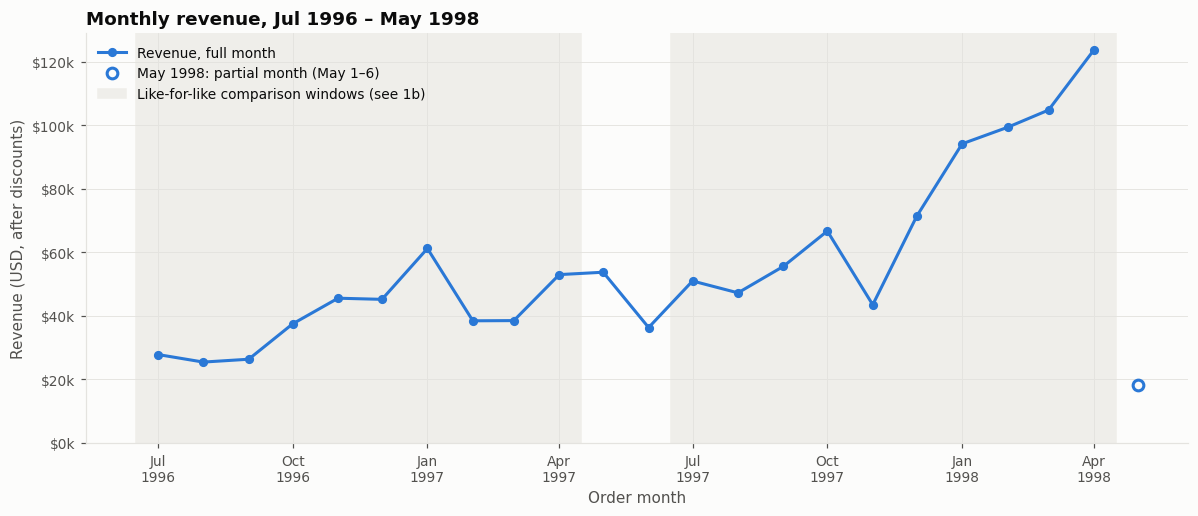


Monthly revenue (USD) and order count:


,Month,orders,revenue,note
0,1996-07,22,"27,861.90",starts Jul 4
1,1996-08,25,"25,485.27",
2,1996-09,23,"26,381.40",
3,1996-10,26,"37,515.72",
4,1996-11,25,"45,600.04",
5,1996-12,31,"45,239.63",
6,1997-01,33,"61,258.07",
7,1997-02,29,"38,483.64",
8,1997-03,30,"38,547.22",
9,1997-04,31,"53,032.95",


In [112]:
# 1a) Revenue over time: monthly, overall
monthly = (sales.groupby("Month")
           .agg(orders=("OrderID", "nunique"), revenue=("Revenue", "sum"))
           .reset_index())
monthly["note"] = ""
monthly.loc[monthly.Month == FIRST_DAY.to_period("M"), "note"] = f"starts {FIRST_DAY:%b} {FIRST_DAY.day}"
if LAST_MONTH_PARTIAL:
    monthly.loc[monthly.Month == LAST_MONTH, "note"] = f"PARTIAL: {LAST_DAY:%b} 1–{LAST_DAY.day} only"
x = monthly.Month.dt.to_timestamp()
full = monthly.Month != LAST_MONTH if LAST_MONTH_PARTIAL else pd.Series(True, index=monthly.index)

fig, ax = plt.subplots(figsize=(11, 4.8))
for _, (a, b) in WINDOWS.items():
    for label, start, end in (a, b):
        # shade from half a month before the first month's point to half a month after the last
        ax.axvspan(pd.Timestamp(start).to_period("M").to_timestamp() - pd.Timedelta(days=15),
                   pd.Timestamp(end).to_period("M").to_timestamp() + pd.Timedelta(days=15),
                   color=WINDOW_SHADE, zorder=0)
ax.plot(x[full], monthly.revenue[full], color=BLUE, marker="o", label="Revenue, full month")
if LAST_MONTH_PARTIAL:
    ax.plot(x[~full], monthly.revenue[~full], linestyle="none", marker="o", markersize=7,
            markerfacecolor=SURFACE, markeredgecolor=BLUE, markeredgewidth=2,
            label=f"{LAST_DAY:%b %Y}: partial month ({LAST_DAY:%b} 1–{LAST_DAY.day})")
ax.yaxis.set_major_formatter(usd_k)
ax.set_ylim(bottom=0)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))
ax.set_xlabel("Order month")
ax.set_ylabel("Revenue (USD, after discounts)")
ax.set_title(f"Monthly revenue, {FIRST_DAY:%b %Y} – {LAST_DAY:%b %Y}")
handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(color=WINDOW_SHADE)); labels.append("Like-for-like comparison windows (see 1b)")
ax.legend(handles, labels, loc="upper left")
plt.tight_layout(); plt.show()
show_table(monthly.assign(Month=monthly.Month.astype(str)), "Monthly revenue (USD) and order count:")

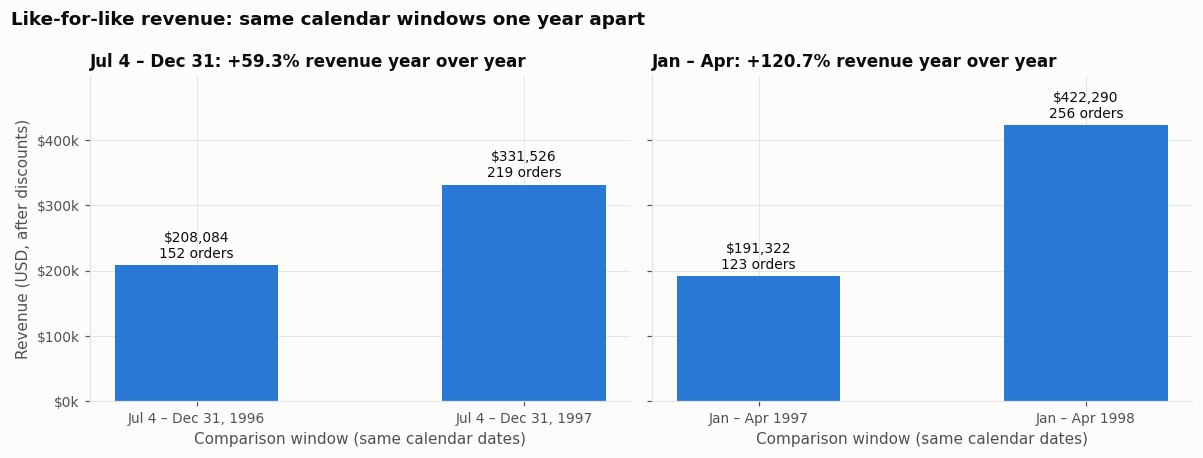


Like-for-like windows (end dates inclusive):


,window,period,start,end,orders,revenue,avg_order_value,revenue_change_pct,orders_change_pct
0,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1996",1996-07-04,1996-12-31,152,"208,083.97","1,368.97",NaN,NaN
1,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1997",1997-07-04,1997-12-31,219,"331,525.55","1,513.82",59.32,44.08
2,Jan – Apr,Jan – Apr 1997,1997-01-01,1997-04-30,123,"191,321.88","1,555.46",NaN,NaN
3,Jan – Apr,Jan – Apr 1998,1998-01-01,1998-04-30,256,"422,290.24","1,649.57",120.72,108.13


In [113]:
# 1b) Like-for-like windows: same calendar dates, one year apart
rows = []
for name, pair in WINDOWS.items():
    for label, start, end in pair:
        w = in_window(sales, start, end)
        rows.append({"window": name, "period": label, "start": start, "end": end,
                     "orders": w.OrderID.nunique(), "revenue": w.Revenue.sum()})
lfl = pd.DataFrame(rows)
lfl["avg_order_value"] = lfl.revenue / lfl.orders
lfl["revenue_change_pct"] = lfl.groupby("window").revenue.pct_change() * 100
lfl["orders_change_pct"] = lfl.groupby("window").orders.pct_change() * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (name, g) in zip(axes, lfl.groupby("window", sort=False)):
    bars = ax.bar(g.period, g.revenue, color=BLUE, width=0.5)
    for bar, (_, r) in zip(bars, g.iterrows()):
        ax.annotate(f"${r.revenue:,.0f}\n{r.orders} orders", (bar.get_x() + bar.get_width() / 2, r.revenue),
                    ha="center", va="bottom", fontsize=9, color=INK, xytext=(0, 3), textcoords="offset points")
    chg = g.revenue_change_pct.iloc[1]
    ax.set_title(f"{name}: {chg:+.1f}% revenue year over year", fontsize=11)
    ax.set_xlabel("Comparison window (same calendar dates)")
    ax.yaxis.set_major_formatter(usd_k)
    ax.margins(y=0.18)
axes[0].set_ylabel("Revenue (USD, after discounts)")
fig.suptitle("Like-for-like revenue: same calendar windows one year apart", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
plt.tight_layout()
fig.savefig(SITE_FIGURES / "figure1.png", dpi=200, bbox_inches="tight")   # Figure 1 on the website
plt.show()
show_table(lfl, "Like-for-like windows (end dates inclusive):")

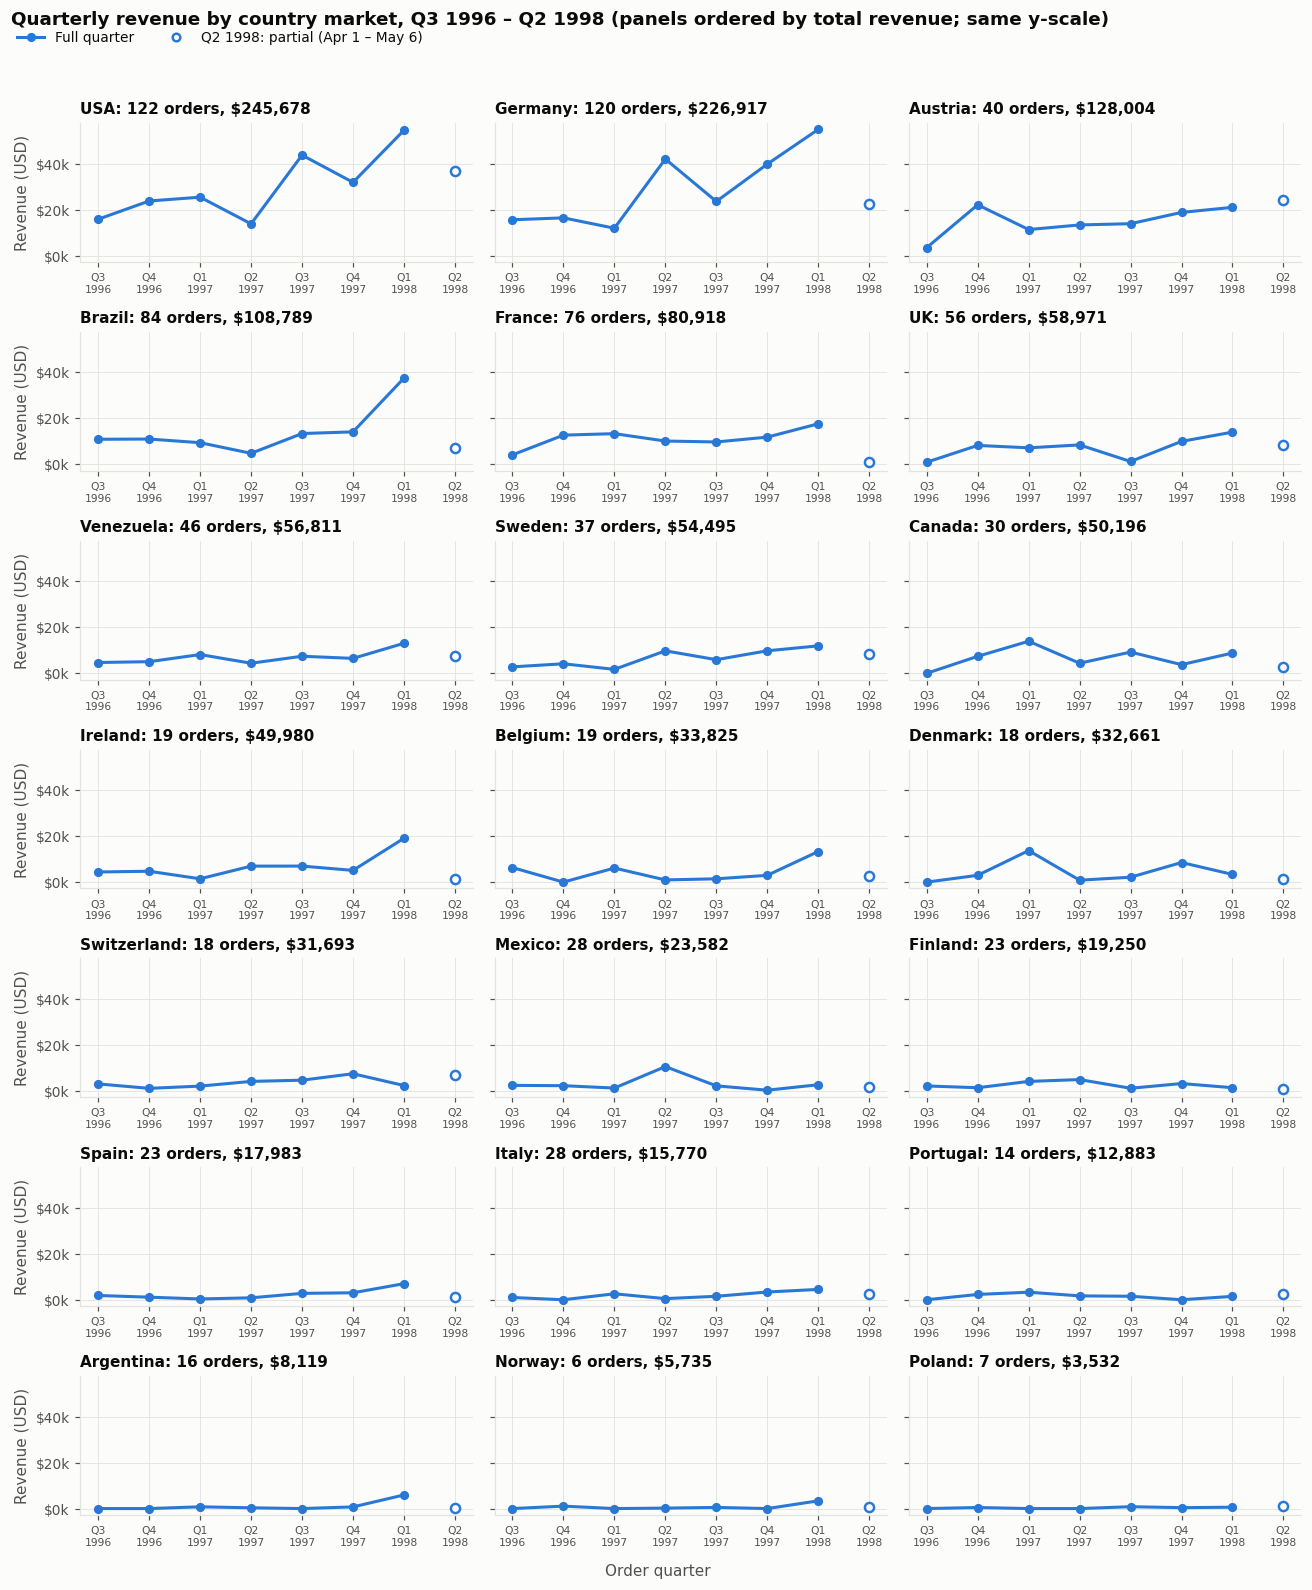


Quarterly revenue (USD) by country:


,1996 Q3,1996 Q4,1997 Q1,1997 Q2,1997 Q3,1997 Q4,1998 Q1,1998 Q2 (partial)
Country,,,,,,,,
USA,"15,841.05","23,769.28","25,421.71","13,834.94","43,711.16","31,877.45","54,532.22","36,690.46"
Germany,"15,607.61","16,431.48","11,929.90","42,017.22","23,575.24","39,797.80","54,893.31","22,664.01"
Austria,"3,488.68","22,112.67","11,349.92","13,354.04","13,894.92","18,802.97","21,007.90","23,992.75"
Brazil,"10,957.62","11,054.60","9,469.82","4,848.82","13,443.55","14,179.00","37,557.34","7,278.43"
France,"4,179.06","12,753.70","13,401.84","10,187.22","9,788.05","11,886.27","17,683.43","1,038.75"
UK,996.20,"8,277.48","7,239.70","8,500.66","1,296.50","10,037.24","14,062.35","8,561.18"
Venezuela,"4,686.50","5,051.60","8,138.38","4,372.00","7,412.25","6,482.29","13,048.01","7,619.60"
Sweden,"2,797.62","4,135.60","1,703.82","9,760.43","5,920.68","9,778.75","11,923.79","8,474.44"
Canada,0.00,"7,372.68","13,933.61","4,382.25","9,225.70","3,756.50","8,813.33","2,712.22"



Quarterly order count by country:


,1996 Q3,1996 Q4,1997 Q1,1997 Q2,1997 Q3,1997 Q4,1998 Q1,1998 Q2 (partial)
Country,,,,,,,,
USA,12,12,10,11,20,19,23,15
Germany,10,12,9,21,17,17,21,13
Austria,2,6,6,3,5,7,6,5
Brazil,10,4,9,6,13,14,22,6
France,6,8,11,8,9,11,20,3
UK,2,8,8,8,3,11,10,6
Venezuela,4,4,6,4,4,6,12,6
Sweden,3,3,4,4,3,6,11,3
Canada,0,4,5,5,5,2,6,3


In [114]:
# 2a) Revenue over time by country market: quarterly, one panel per country, shared y-axis.
# Quarterly rather than monthly because many countries have only a handful of orders a month.
sales["Quarter"] = sales["OrderDate"].dt.to_period("Q")
first_q, last_q = FIRST_DAY.to_period("Q"), LAST_DAY.to_period("Q")
LAST_Q_PARTIAL = LAST_DAY < last_q.to_timestamp(how="end").normalize()
quarters = pd.period_range(first_q, last_q, freq="Q")

country_q_rev = sales.pivot_table(index="Quarter", columns="Country", values="Revenue",
                                  aggfunc="sum", fill_value=0).reindex(quarters, fill_value=0)
country_q_orders = sales.pivot_table(index="Quarter", columns="Country", values="OrderID",
                                     aggfunc="nunique", fill_value=0).reindex(quarters, fill_value=0)
country_totals = (sales.groupby("Country")
                  .agg(orders=("OrderID", "nunique"), revenue=("Revenue", "sum"))
                  .sort_values("revenue", ascending=False))

ncols = 3
nrows = -(-len(country_totals) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.1 * nrows), sharex=True, sharey=True)
qx = range(len(quarters))
full_q = [not (LAST_Q_PARTIAL and q == last_q) for q in quarters]
for ax, (country, tot) in zip(axes.flat, country_totals.iterrows()):
    y = country_q_rev[country].values
    ax.plot([i for i in qx if full_q[i]], [y[i] for i in qx if full_q[i]], color=BLUE, marker="o")
    if LAST_Q_PARTIAL:
        ax.plot([len(quarters) - 1], [y[-1]], linestyle="none", marker="o", markersize=6,
                markerfacecolor=SURFACE, markeredgecolor=BLUE, markeredgewidth=1.6)
    ax.set_title(f"{country}: {int(tot.orders)} orders, ${tot.revenue:,.0f}", fontsize=10)
    ax.yaxis.set_major_formatter(usd_k)
for ax in axes.flat[len(country_totals):]:
    ax.set_visible(False)
qlabels = [f"Q{q.quarter}\n{q.year}" for q in quarters]
for ax in axes[-1]:
    ax.set_xticks(list(qx)); ax.set_xticklabels(qlabels)
for ax in axes.flat:
    ax.tick_params(labelbottom=True)
    ax.set_xticks(list(qx)); ax.set_xticklabels(qlabels, fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel("Revenue (USD)")
fig.supxlabel("Order quarter", color=INK_2, fontsize=10)
fig.legend(handles=[Line2D([], [], color=BLUE, marker="o", label="Full quarter"),
                    Line2D([], [], linestyle="none", marker="o", markerfacecolor=SURFACE, markeredgecolor=BLUE,
                           markeredgewidth=1.6, label=f"Q{last_q.quarter} {last_q.year}: partial "
                                                      f"({last_q.start_time:%b} 1 – {LAST_DAY:%b} {LAST_DAY.day})")],
           loc="upper left", ncol=2, bbox_to_anchor=(0.005, 0.975))
fig.suptitle(f"Quarterly revenue by country market, Q{first_q.quarter} {first_q.year} – "
             f"Q{last_q.quarter} {last_q.year} (panels ordered by total revenue; same y-scale)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.955)); plt.show()

q_index = [f"{q.year} Q{q.quarter}" + (" (partial)" if LAST_Q_PARTIAL and q == last_q else "") for q in quarters]
show_table(country_q_rev[country_totals.index].set_axis(q_index).T, "Quarterly revenue (USD) by country:")
show_table(country_q_orders[country_totals.index].set_axis(q_index).T, "Quarterly order count by country:")

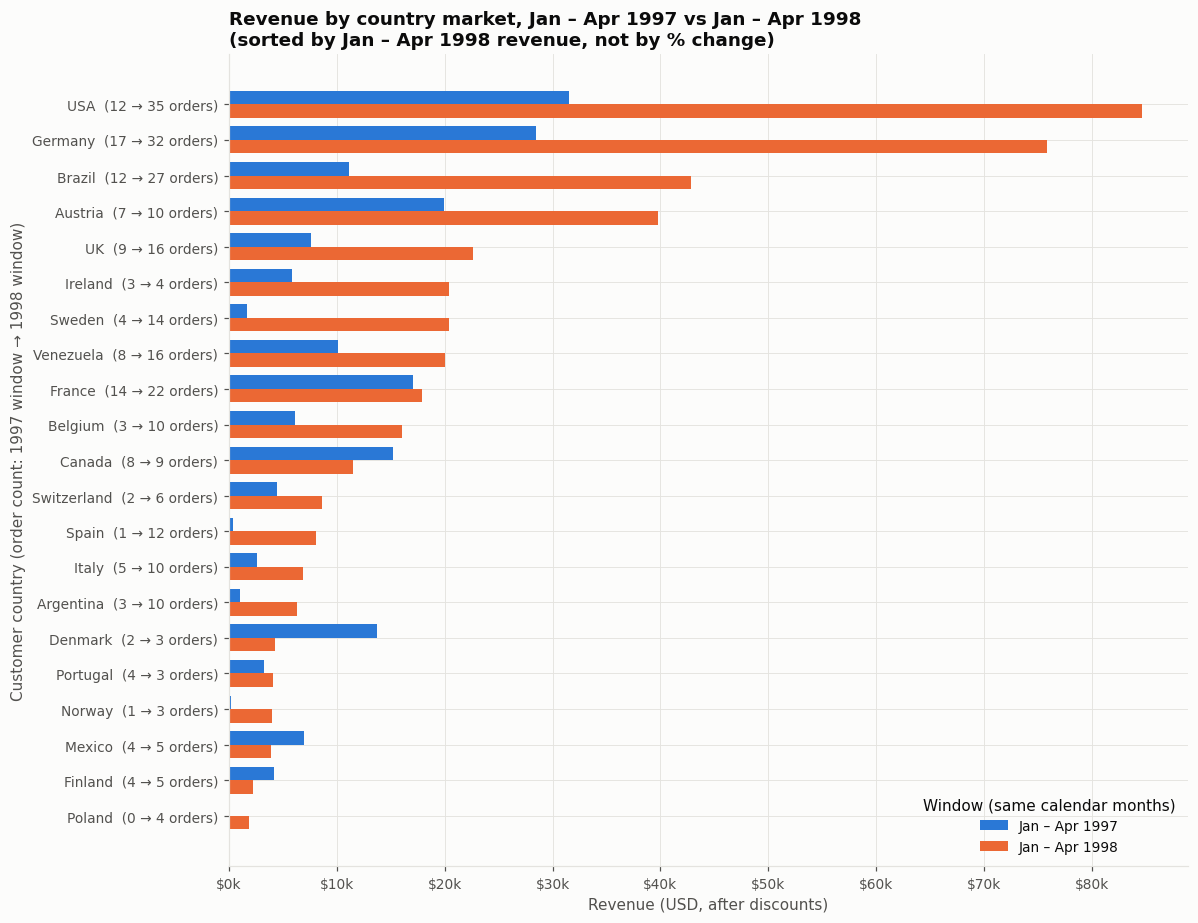


Revenue (USD) and orders by country, Jan – Apr 1997 vs Jan – Apr 1998. % change is blank where the earlier window had no revenue; read it alongside order counts:


,orders_Jan – Apr 1997,revenue_Jan – Apr 1997,orders_Jan – Apr 1998,revenue_Jan – Apr 1998,revenue_change,revenue_change_pct,low_volume (<5 orders in a window)
Country,,,,,,,
USA,12,"31,517.75",35,"84,707.80","53,190.05",168.76,False
Germany,17,"28,433.64",32,"75,840.50","47,406.86",166.73,False
Brazil,12,"11,097.12",27,"42,808.69","31,711.57",285.76,False
Austria,7,"19,973.37",10,"39,782.65","19,809.28",99.18,False
UK,9,"7,591.70",16,"22,623.53","15,031.83",198.00,False
Ireland,3,"5,870.93",4,"20,402.12","14,531.20",247.51,True
Sweden,4,"1,703.82",14,"20,398.23","18,694.41","1,097.21",True
Venezuela,8,"10,125.38",16,"19,993.69","9,868.31",97.46,False
France,14,"17,083.50",22,"17,929.43",845.93,4.95,False


In [115]:
# 2b) Like-for-like by country: Jan–Apr 1997 vs Jan–Apr 1998, sorted by 1998-window revenue (not by % change)
(a_label, a_start, a_end), (b_label, b_start, b_end) = RECENT
def by_country(start, end):
    """Total orders and revenue by customer country within a window.

    Args:
        start (str): First day of the window, e.g. "1997-01-01".
        end (str): Last day of the window, inclusive.

    Returns:
        pandas.DataFrame: Indexed by country, with ``orders`` (distinct
        orders) and ``revenue`` (USD) from ``sales``; countries with no
        orders in the window are absent.
    """
    return in_window(sales, start, end).groupby("Country").agg(orders=("OrderID", "nunique"),
                                                               revenue=("Revenue", "sum"))
cw = (by_country(a_start, a_end).add_suffix(f"_{a_label}")
      .join(by_country(b_start, b_end).add_suffix(f"_{b_label}"), how="outer")
      .reindex(country_totals.index).fillna(0))
for c in cw.columns:
    if c.startswith("orders"):
        cw[c] = cw[c].astype(int)
cw["revenue_change"] = cw[f"revenue_{b_label}"] - cw[f"revenue_{a_label}"]
cw["revenue_change_pct"] = (cw["revenue_change"] / cw[f"revenue_{a_label}"].where(cw[f"revenue_{a_label}"] > 0)) * 100
cw["low_volume (<5 orders in a window)"] = (cw[[f"orders_{a_label}", f"orders_{b_label}"]] < 5).any(axis=1)
cw = cw.sort_values(f"revenue_{b_label}", ascending=False)

fig, ax = plt.subplots(figsize=(11, 8.5))
yy = range(len(cw))
h = 0.38
ax.barh([i - h / 2 for i in yy], cw[f"revenue_{a_label}"], height=h, color=BLUE, label=a_label)
ax.barh([i + h / 2 for i in yy], cw[f"revenue_{b_label}"], height=h, color=ORANGE, label=b_label)
ax.set_yticks(list(yy))
ax.set_yticklabels([f"{c}  ({r[f'orders_{a_label}']} → {r[f'orders_{b_label}']} orders)" for c, r in cw.iterrows()])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(usd_k)
ax.set_xlabel("Revenue (USD, after discounts)")
ax.set_ylabel("Customer country (order count: 1997 window → 1998 window)")
ax.set_title(f"Revenue by country market, {a_label} vs {b_label}\n(sorted by {b_label} revenue, not by % change)")
ax.legend(title="Window (same calendar months)", loc="lower right")
plt.tight_layout(); plt.show()
show_table(cw, f"Revenue (USD) and orders by country, {a_label} vs {b_label}. "
               "% change is blank where the earlier window had no revenue; read it alongside order counts:")

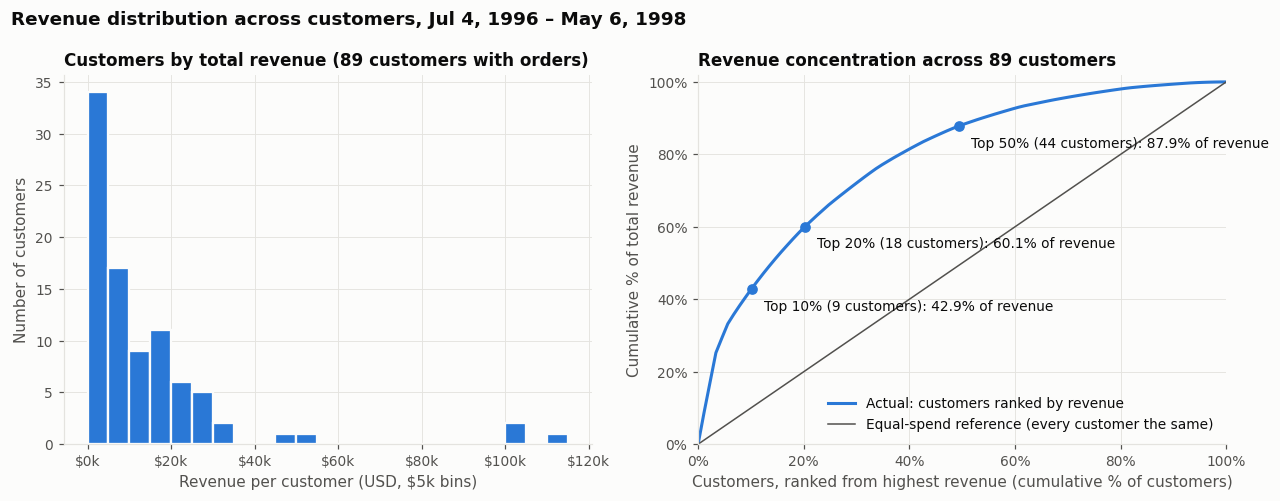


Revenue concentration:


,group,customers,revenue,share_pct
0,Top customer,1,"110,277.31",8.71
1,Top 5 customers,5,"420,591.94",33.23
2,Top 10 customers,10,"570,145.05",45.04
3,Top 10% of customers,9,"542,781.45",42.88
4,Top 20% of customers,18,"760,197.94",60.06
5,Top 50% of customers,44,"1,112,467.27",87.89
6,All customers,89,"1,265,793.04",100.00



Revenue per customer, summary statistics:


,count,mean,std,min,10%,25%,50%,75%,90%,max
revenue per customer (USD),89.00,"14,222.39","20,219.90",100.80,"1,534.30","3,239.80","7,176.22","16,817.10","27,665.32","110,277.31"



All customers ranked by revenue:


,rank,CustomerID,CompanyName,Country,orders,revenue,share_pct,cumulative_share_pct
0,1,QUICK,QUICK-Stop,Germany,28,"110,277.31",8.71,8.71
1,2,ERNSH,Ernst Handel,Austria,30,"104,874.98",8.29,17.00
2,3,SAVEA,Save-a-lot Markets,USA,31,"104,361.95",8.24,25.24
3,4,RATTC,Rattlesnake Canyon Grocery,USA,18,"51,097.80",4.04,29.28
4,5,HUNGO,Hungry Owl All-Night Grocers,Ireland,19,"49,979.90",3.95,33.23
5,6,HANAR,Hanari Carnes,Brazil,14,"32,841.37",2.59,35.82
6,7,KOENE,Königlich Essen,Germany,14,"30,908.38",2.44,38.26
7,8,FOLKO,Folk och fä HB,Sweden,19,"29,567.56",2.34,40.60
8,9,MEREP,Mère Paillarde,Canada,13,"28,872.19",2.28,42.88
9,10,WHITC,White Clover Markets,USA,14,"27,363.60",2.16,45.04



Customers with no orders (not in the charts): FISSA FISSA Fabrica Inter. Salchichas S.A., PARIS Paris spécialités


In [116]:
# 3) Revenue distribution across customers (all orders, full date range)
cust = (sales.groupby(["CustomerID", "CompanyName", "Country"])
        .agg(orders=("OrderID", "nunique"), revenue=("Revenue", "sum"))
        .reset_index().sort_values("revenue", ascending=False).reset_index(drop=True))
cust["rank"] = cust.index + 1
cust["share_pct"] = cust.revenue / cust.revenue.sum() * 100
cust["cumulative_share_pct"] = cust.share_pct.cumsum()
cust["cumulative_customers_pct"] = cust["rank"] / len(cust) * 100
no_orders = customers[~customers.CustomerID.isin(sales.CustomerID)]

span = f"{FIRST_DAY:%b} {FIRST_DAY.day}, {FIRST_DAY.year} – {LAST_DAY:%b} {LAST_DAY.day}, {LAST_DAY.year}"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
bin_width = 5000
bins = range(0, int(cust.revenue.max() // bin_width + 2) * bin_width, bin_width)
ax1.hist(cust.revenue, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax1.xaxis.set_major_formatter(usd_k)
ax1.set_xlabel(f"Revenue per customer (USD, ${bin_width / 1000:.0f}k bins)")
ax1.set_ylabel("Number of customers")
ax1.set_title(f"Customers by total revenue ({len(cust)} customers with orders)", fontsize=11)

ax2.plot([0] + cust.cumulative_customers_pct.tolist(), [0] + cust.cumulative_share_pct.tolist(),
         color=BLUE, label="Actual: customers ranked by revenue")
ax2.plot([0, 100], [0, 100], color=INK_2, linewidth=1, label="Equal-spend reference (every customer the same)")
for pct in (10, 20, 50):
    n = round(len(cust) * pct / 100)
    share = cust.share_pct.iloc[:n].sum()
    ax2.plot(n / len(cust) * 100, share, marker="o", color=BLUE, markersize=6)
    ax2.annotate(f"Top {pct}% ({n} customers): {share:.1f}% of revenue", (n / len(cust) * 100, share),
                 xytext=(8, -14), textcoords="offset points", fontsize=9, color=INK)
ax2.set_xlim(0, 100); ax2.set_ylim(0, 102)
ax2.xaxis.set_major_formatter(mticker.PercentFormatter())
ax2.yaxis.set_major_formatter(mticker.PercentFormatter())
ax2.set_xlabel("Customers, ranked from highest revenue (cumulative % of customers)")
ax2.set_ylabel("Cumulative % of total revenue")
ax2.set_title(f"Revenue concentration across {len(cust)} customers", fontsize=11)
ax2.legend(loc="lower right")
fig.suptitle(f"Revenue distribution across customers, {span}", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()

conc = pd.DataFrame([{"group": ("Top customer" if k == 1 else f"Top {k} customers") if isinstance(k, int) else k,
                      "customers": n, "revenue": cust.revenue.iloc[:n].sum(),
                      "share_pct": cust.share_pct.iloc[:n].sum()}
                     for k, n in [(1, 1), (5, 5), (10, 10), ("Top 10% of customers", round(len(cust) * .1)),
                                  ("Top 20% of customers", round(len(cust) * .2)),
                                  ("Top 50% of customers", round(len(cust) * .5)), ("All customers", len(cust))]])
show_table(conc, "Revenue concentration:")
show_table(cust.revenue.describe(percentiles=[.1, .25, .5, .75, .9]).to_frame("revenue per customer (USD)").T,
           "Revenue per customer, summary statistics:")
show_table(cust[["rank", "CustomerID", "CompanyName", "Country", "orders", "revenue", "share_pct",
                 "cumulative_share_pct"]], "All customers ranked by revenue:")
print(f"\nCustomers with no orders (not in the charts): {', '.join(no_orders.CustomerID + ' ' + no_orders.CompanyName)}")

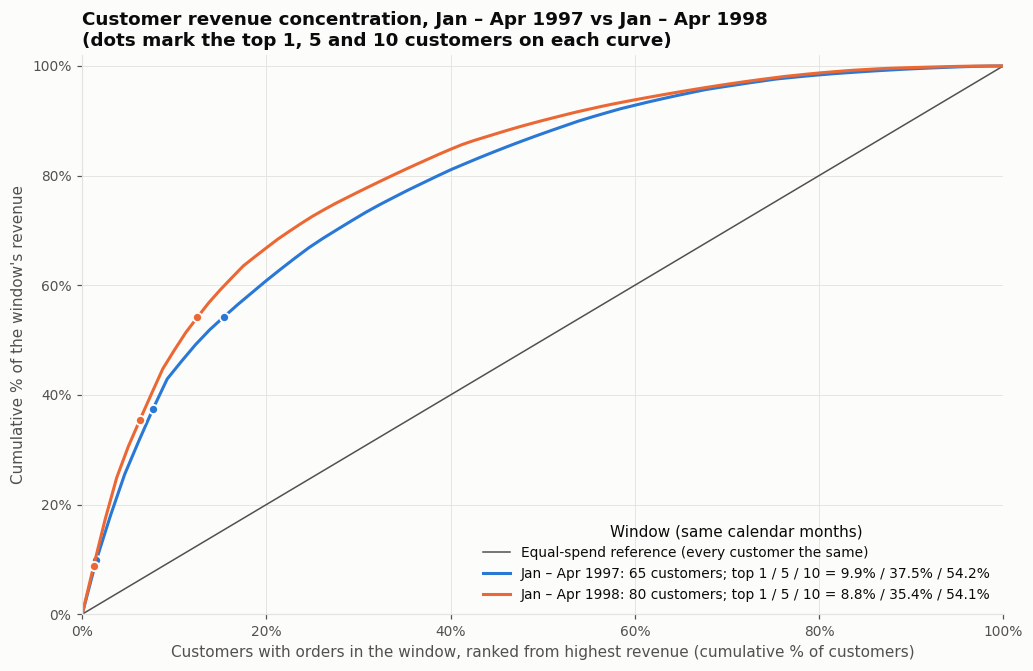


Concentration by window. Customer counts differ, so the top 10 is a different share of each window's customers (last column); the curve's x-axis normalizes for that:


,window,start,end,customers_with_orders,orders,revenue,top1_share_pct,top5_share_pct,top10_share_pct,top10_as_pct_of_customers
0,Jan – Apr 1997,1997-01-01,1997-04-30,65,123,"191,321.88",9.87,37.46,54.24,15.38
1,Jan – Apr 1998,1998-01-01,1998-04-30,80,256,"422,290.24",8.81,35.38,54.14,12.50



Full cumulative distribution, Jan – Apr 1997 (65 customers):


,rank,CustomerID,CompanyName,Country,orders,revenue,share_pct,cumulative_share_pct,cumulative_customers_pct
0,1,ERNSH,Ernst Handel,Austria,5,"18,883.17",9.87,9.87,1.54
1,2,QUICK,QUICK-Stop,Germany,3,"15,585.76",8.15,18.02,3.08
2,3,RATTC,Rattlesnake Canyon Grocery,USA,2,"14,364.20",7.51,25.52,4.62
3,4,SAVEA,Save-a-lot Markets,USA,3,"11,650.18",6.09,31.61,6.15
4,5,SIMOB,Simons bistro,Denmark,1,"11,188.40",5.85,37.46,7.69
5,6,MEREP,Mère Paillarde,Canada,3,"10,420.46",5.45,42.91,9.23
6,7,SUPRD,Suprêmes délices,Belgium,3,"6,109.48",3.19,46.10,10.77
7,8,HUNGO,Hungry Owl All-Night Grocers,Ireland,3,"5,870.93",3.07,49.17,12.31
8,9,HILAA,HILARIÓN-Abastos,Venezuela,4,"5,190.68",2.71,51.88,13.85
9,10,BOTTM,Bottom-Dollar Markets,Canada,4,"4,512.25",2.36,54.24,15.38



Full cumulative distribution, Jan – Apr 1998 (80 customers):


,rank,CustomerID,CompanyName,Country,orders,revenue,share_pct,cumulative_share_pct,cumulative_customers_pct
0,1,QUICK,QUICK-Stop,Germany,8,"37,217.32",8.81,8.81,1.25
1,2,ERNSH,Ernst Handel,Austria,8,"35,992.65",8.52,17.34,2.50
2,3,SAVEA,Save-a-lot Markets,USA,10,"31,979.71",7.57,24.91,3.75
3,4,HANAR,Hanari Carnes,Brazil,7,"23,821.20",5.64,30.55,5.00
4,5,HUNGO,Hungry Owl All-Night Grocers,Ireland,4,"20,402.12",4.83,35.38,6.25
5,6,RATTC,Rattlesnake Canyon Grocery,USA,5,"19,982.55",4.73,40.11,7.50
6,7,KOENE,Königlich Essen,Germany,4,"19,582.77",4.64,44.75,8.75
7,8,WHITC,White Clover Markets,USA,3,"14,350.15",3.40,48.15,10.00
8,9,FOLKO,Folk och fä HB,Sweden,9,"13,644.07",3.23,51.38,11.25
9,10,SUPRD,Suprêmes délices,Belgium,6,"11,644.60",2.76,54.14,12.50



6 of the top 10 customers are the same in both windows: ERNSH, QUICK, RATTC, SAVEA, SUPRD, HUNGO

Top-10 customers in either window (rank <NA> = no orders in that window):


,CustomerID,CompanyName,rank_Jan – Apr 1997,revenue_Jan – Apr 1997,rank_Jan – Apr 1998,revenue_Jan – Apr 1998,top10_in
0,QUICK,QUICK-Stop,2,"15,585.76",1,"37,217.32",both
1,ERNSH,Ernst Handel,1,"18,883.17",2,"35,992.65",both
2,SAVEA,Save-a-lot Markets,4,"11,650.18",3,"31,979.71",both
3,HUNGO,Hungry Owl All-Night Grocers,8,"5,870.93",5,"20,402.12",both
4,RATTC,Rattlesnake Canyon Grocery,3,"14,364.20",6,"19,982.55",both
5,SUPRD,Suprêmes délices,7,"6,109.48",10,"11,644.60",both
6,HANAR,Hanari Carnes,<NA>,0.00,4,"23,821.20",Jan – Apr 1998 only
7,KOENE,Königlich Essen,17,"3,275.00",7,"19,582.77",Jan – Apr 1998 only
8,WHITC,White Clover Markets,19,"3,013.97",8,"14,350.15",Jan – Apr 1998 only
9,FOLKO,Folk och fä HB,50,497.22,9,"13,644.07",Jan – Apr 1998 only


In [117]:
# 3b) Customer concentration in the like-for-like windows (Jan–Apr 1997 vs Jan–Apr 1998),
# so the comparison covers the same calendar months instead of the whole, uneven date range.
(a_label, a_start, a_end), (b_label, b_start, b_end) = RECENT
WINDOW_COLORS = {a_label: BLUE, b_label: ORANGE}    # earlier window = slot 1, later = slot 2

def ranked_customers(start, end):
    """Rank the customers who ordered within a window by revenue.

    Args:
        start (str): First day of the window, e.g. "1997-01-01".
        end (str): Last day of the window, inclusive.

    Returns:
        pandas.DataFrame: One row per customer with orders in the
        window, highest revenue first: rank, CustomerID, CompanyName,
        Country, orders, revenue (USD), share_pct,
        cumulative_share_pct and cumulative_customers_pct.
    """
    c = (in_window(sales, start, end)
         .groupby(["CustomerID", "CompanyName", "Country"])
         .agg(orders=("OrderID", "nunique"), revenue=("Revenue", "sum"))
         .reset_index().sort_values("revenue", ascending=False).reset_index(drop=True))
    c.insert(0, "rank", c.index + 1)
    c["share_pct"] = c.revenue / c.revenue.sum() * 100
    c["cumulative_share_pct"] = c.share_pct.cumsum()
    c["cumulative_customers_pct"] = c["rank"] / len(c) * 100
    return c

ranked = {label: ranked_customers(start, end) for label, start, end in RECENT}

summary = pd.DataFrame([{
    "window": label, "start": start, "end": end,
    "customers_with_orders": len(ranked[label]),
    "orders": int(ranked[label].orders.sum()),
    "revenue": ranked[label].revenue.sum(),
    "top1_share_pct": ranked[label].share_pct.iloc[:1].sum(),
    "top5_share_pct": ranked[label].share_pct.iloc[:5].sum(),
    "top10_share_pct": ranked[label].share_pct.iloc[:10].sum(),
    "top10_as_pct_of_customers": 10 / len(ranked[label]) * 100,
} for label, start, end in RECENT])

fig, ax = plt.subplots(figsize=(9.5, 6.2))
ax.plot([0, 100], [0, 100], color=INK_2, linewidth=1, label="Equal-spend reference (every customer the same)")
for label, c in ranked.items():
    s = summary.set_index("window").loc[label]
    ax.plot([0] + c.cumulative_customers_pct.tolist(), [0] + c.cumulative_share_pct.tolist(),
            color=WINDOW_COLORS[label],
            label=(f"{label}: {len(c)} customers; top 1 / 5 / 10 = "
                   f"{s.top1_share_pct:.1f}% / {s.top5_share_pct:.1f}% / {s.top10_share_pct:.1f}%"))
    for k in (1, 5, 10):   # mark the top-1, top-5 and top-10 points on each curve
        ax.plot(c.cumulative_customers_pct.iloc[k - 1], c.cumulative_share_pct.iloc[k - 1], marker="o",
                markersize=6, color=WINDOW_COLORS[label], markeredgecolor=SURFACE, markeredgewidth=1.2)
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xlabel("Customers with orders in the window, ranked from highest revenue (cumulative % of customers)")
ax.set_ylabel("Cumulative % of the window's revenue")
ax.set_title(f"Customer revenue concentration, {a_label} vs {b_label}\n"
             "(dots mark the top 1, 5 and 10 customers on each curve)")
ax.legend(loc="lower right", title="Window (same calendar months)")
plt.tight_layout()
fig.savefig(SITE_FIGURES / "figure3.png", dpi=200, bbox_inches="tight")   # Figure 3 on the website
plt.show()

show_table(summary, "Concentration by window. Customer counts differ, so the top 10 is a different "
                    "share of each window's customers (last column); the curve's x-axis normalizes for that:")
for label, c in ranked.items():
    show_table(c[["rank", "CustomerID", "CompanyName", "Country", "orders", "revenue", "share_pct",
                  "cumulative_share_pct", "cumulative_customers_pct"]],
               f"Full cumulative distribution, {label} ({len(c)} customers):")

# Are the top 10 the same customers in both windows?
top_a = ranked[a_label].head(10).set_index("CustomerID")
top_b = ranked[b_label].head(10).set_index("CustomerID")
rank_a = ranked[a_label].set_index("CustomerID")["rank"]
rank_b = ranked[b_label].set_index("CustomerID")["rank"]
both = top_a.index.intersection(top_b.index)
overlap = pd.DataFrame({"CustomerID": top_a.index.union(top_b.index, sort=False)})
overlap["CompanyName"] = overlap.CustomerID.map(customers.set_index("CustomerID").CompanyName)
overlap[f"rank_{a_label}"] = overlap.CustomerID.map(rank_a).astype("Int64")      # <NA> = no orders in the window
overlap[f"revenue_{a_label}"] = overlap.CustomerID.map(ranked[a_label].set_index("CustomerID").revenue).fillna(0)
overlap[f"rank_{b_label}"] = overlap.CustomerID.map(rank_b).astype("Int64")
overlap[f"revenue_{b_label}"] = overlap.CustomerID.map(ranked[b_label].set_index("CustomerID").revenue).fillna(0)
overlap["top10_in"] = overlap.CustomerID.map(
    lambda c: "both" if c in both else (f"{a_label} only" if c in top_a.index else f"{b_label} only"))
overlap = overlap.sort_values(["top10_in", f"rank_{b_label}"], key=lambda s: s.map(
    {"both": 0, f"{b_label} only": 1, f"{a_label} only": 2}) if s.name == "top10_in" else s)
print(f"\n{len(both)} of the top 10 customers are the same in both windows: {', '.join(both)}")
show_table(overlap.reset_index(drop=True),
           f"Top-10 customers in either window (rank <NA> = no orders in that window):")

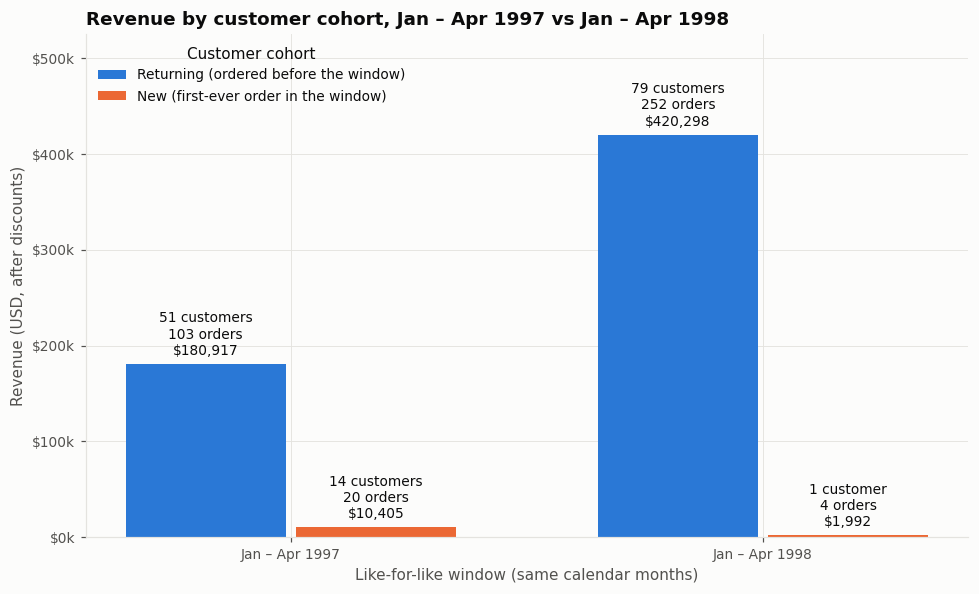


Customer cohorts by window (first-ever order measured from Jul 4, 1996, the start of the data):


,window,cohort,customers,orders,revenue,share_of_window_revenue_pct,orders_per_customer,revenue_per_customer
0,Jan – Apr 1997,Returning (ordered before the window),51,103,"180,916.94",94.56,2.02,"3,547.39"
1,Jan – Apr 1997,New (first-ever order in the window),14,20,"10,404.94",5.44,1.43,743.21
2,Jan – Apr 1997,All customers in window,65,123,"191,321.88",100.00,1.89,"2,943.41"
3,Jan – Apr 1998,Returning (ordered before the window),79,252,"420,298.19",99.53,3.19,"5,320.23"
4,Jan – Apr 1998,New (first-ever order in the window),1,4,"1,992.05",0.47,4.00,"1,992.05"
5,Jan – Apr 1998,All customers in window,80,256,"422,290.24",100.00,3.20,"5,278.63"



Customers in the Customers tab with no orders at all: 2 of 91

Customers with no orders:


,CustomerID,CompanyName,Country
0,FISSA,FISSA Fabrica Inter. Salchichas S.A.,Spain
1,PARIS,Paris spécialités,France


In [118]:
# 3c) Customer cohorts within each like-for-like window (Jan–Apr 1997, Jan–Apr 1998).
# "New" = the customer's first-ever order falls inside the window.
# "Returning" = the customer had ordered before the window started.
# First-ever order is taken from the Orders tab, which starts on Jul 4, 1996; no earlier history is available.
first_order = orders.groupby("CustomerID")["OrderDate"].min()
COHORTS = {"Returning (ordered before the window)": BLUE,       # fixed order: slot 1, slot 2
           "New (first-ever order in the window)": ORANGE}
RETURNING, NEW = COHORTS

rows = []
for label, start, end in RECENT:
    w = in_window(sales, start, end).copy()
    w["cohort"] = (w.CustomerID.map(first_order) >= pd.Timestamp(start)).map({True: NEW, False: RETURNING})
    window_revenue = w.Revenue.sum()
    for cohort in COHORTS:
        g = w[w.cohort == cohort]
        rows.append({"window": label, "cohort": cohort, "customers": g.CustomerID.nunique(),
                     "orders": g.OrderID.nunique(), "revenue": g.Revenue.sum(),
                     "share_of_window_revenue_pct": g.Revenue.sum() / window_revenue * 100})
    rows.append({"window": label, "cohort": "All customers in window", "customers": w.CustomerID.nunique(),
                 "orders": w.OrderID.nunique(), "revenue": window_revenue, "share_of_window_revenue_pct": 100.0})
cohort_tbl = pd.DataFrame(rows)
cohort_tbl["orders_per_customer"] = cohort_tbl.orders / cohort_tbl.customers
cohort_tbl["revenue_per_customer"] = cohort_tbl.revenue / cohort_tbl.customers

never = customers[~customers.CustomerID.isin(orders.CustomerID)]

# Grouped bars: one group per window, one bar per cohort, labeled with the cohort's customer count
plot_tbl = cohort_tbl[cohort_tbl.cohort.isin(COHORTS)]
fig, ax = plt.subplots(figsize=(9, 5.5))
width = 0.36
windows = [label for label, _, _ in RECENT]
for j, (cohort, color) in enumerate(COHORTS.items()):
    g = plot_tbl[plot_tbl.cohort == cohort].set_index("window").loc[windows]
    xs = [i + (j - 0.5) * width for i in range(len(windows))]
    ax.bar(xs, g.revenue, width=width * 0.94, color=color, label=cohort)
    for x, (_, r) in zip(xs, g.iterrows()):
        ax.annotate(f"{r.customers} customer{'s' if r.customers != 1 else ''}\n"
                    f"{r.orders} order{'s' if r.orders != 1 else ''}\n${r.revenue:,.0f}", (x, r.revenue),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(range(len(windows)))
ax.set_xticklabels(windows)
ax.yaxis.set_major_formatter(usd_k)
ax.margins(y=0.25)
ax.set_xlabel("Like-for-like window (same calendar months)")
ax.set_ylabel("Revenue (USD, after discounts)")
ax.set_title(f"Revenue by customer cohort, {windows[0]} vs {windows[1]}")
ax.legend(title="Customer cohort", loc="upper left")
plt.tight_layout()
fig.savefig(SITE_FIGURES / "figure2.png", dpi=200, bbox_inches="tight")   # Figure 2 on the website
plt.show()

show_table(cohort_tbl, "Customer cohorts by window (first-ever order measured from Jul 4, 1996, the start of the data):")
print(f"\nCustomers in the Customers tab with no orders at all: {len(never)} of {len(customers)}")
show_table(never[["CustomerID", "CompanyName", "Country"]].reset_index(drop=True), "Customers with no orders:")

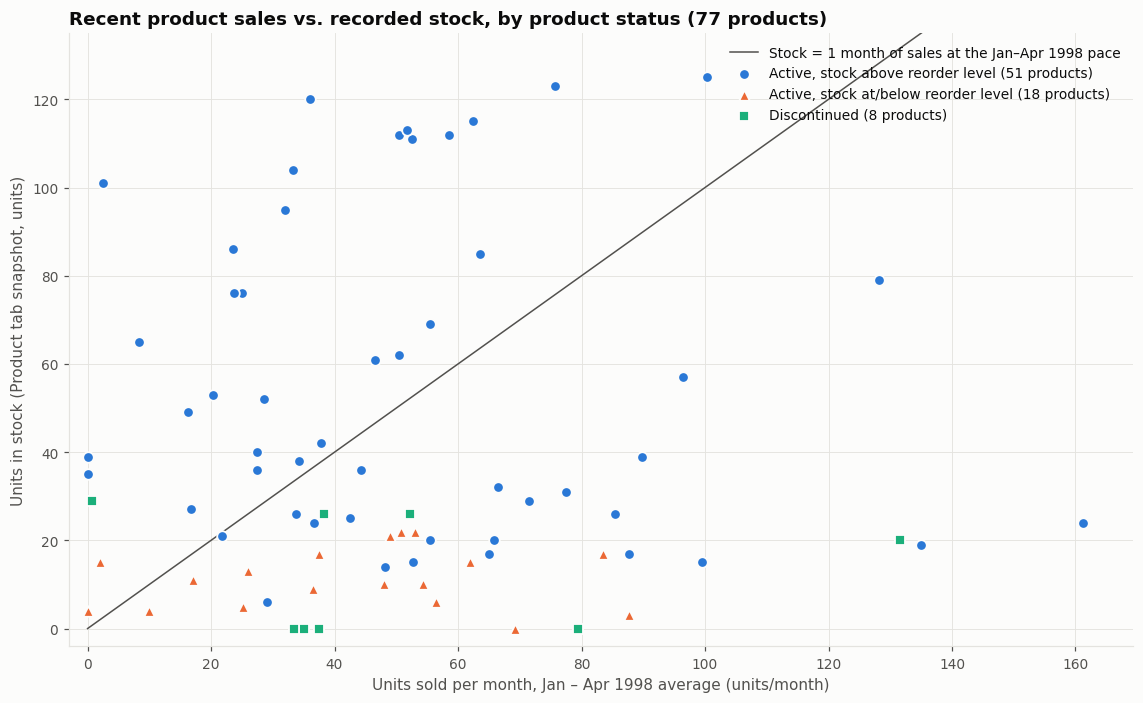


Products by status (unit totals):


,status,products,units_Jan – Apr 1997,units_Jan – Apr 1998,UnitsInStock,UnitsOnOrder
0,"Active, stock above reorder level",51,5196,10620,2814,0
1,"Active, stock at/below reorder level",18,2105,3073,204,780
2,Discontinued,8,914,1633,101,0



All products (sorted by status, then units sold in the recent window):


,ProductName,CategoryName,status,UnitsInStock,UnitsOnOrder,ReorderLevel,units_Jan – Apr 1997,units_Jan – Apr 1998,units_per_month_recent,months_of_stock_at_recent_pace,units_all_time,orders_all_time,revenue_all_time,last_order
ProductID,,,,,,,,,,,,,,
13,Konbu,Seafood,"Active, stock above reorder level",24,0,5,13,645,161.25,0.15,891,40,"4,960.44",1998-05-06
60,Camembert Pierrot,Dairy Products,"Active, stock above reorder level",19,0,0,226,540,135.00,0.14,1577,51,"46,825.48",1998-05-06
59,Raclette Courdavault,Dairy Products,"Active, stock above reorder level",79,0,0,317,513,128.25,0.62,1496,54,"71,155.70",1998-04-20
75,Rhönbräu Klosterbier,Beverages,"Active, stock above reorder level",125,0,25,160,401,100.25,1.25,1155,46,"8,177.49",1998-05-06
7,Uncle Bob's Organic Dried Pears,Produce,"Active, stock above reorder level",15,0,10,96,398,99.50,0.15,763,29,"22,044.30",1998-05-06
76,Lakkalikööri,Beverages,"Active, stock above reorder level",57,0,20,94,386,96.50,0.59,981,39,"15,760.44",1998-05-06
1,Chai,Beverages,"Active, stock above reorder level",39,0,10,89,359,89.75,0.43,828,38,"12,788.10",1998-05-05
62,Tarte au sucre,Confections,"Active, stock above reorder level",17,0,0,113,351,87.75,0.19,1083,48,"47,234.97",1998-04-23
71,Fløtemysost,Dairy Products,"Active, stock above reorder level",26,0,0,169,342,85.50,0.30,1057,42,"19,551.03",1998-04-21


In [119]:
# 4) Product-level sales activity vs. what the Product tab records (status, stock, reorder level).
# Note: the Product tab is a single snapshot with no date, so stock and reorder level are compared
# against recent sales (Jan–Apr 1998, the latest full months), not against history.
(a_label, a_start, a_end), (b_label, b_start, b_end) = RECENT
n_months_b = len(pd.period_range(b_start, b_end, freq="M"))

def units_in(start, end):
    """Total units sold per product within a window.

    Args:
        start (str): First day of the window, e.g. "1997-01-01".
        end (str): Last day of the window, inclusive.

    Returns:
        pandas.Series: Units sold, indexed by ProductID; products with
        no sales in the window are absent.
    """
    return in_window(sales, start, end).groupby("ProductID").Quantity.sum()

prod = (products[["ProductID", "ProductName", "CategoryID", "Discontinued", "UnitsInStock",
                  "UnitsOnOrder", "ReorderLevel"]]
        .merge(data["Categories"][["CategoryID", "CategoryName"]], on="CategoryID")
        .set_index("ProductID"))
agg = sales.groupby("ProductID").agg(units_all_time=("Quantity", "sum"), revenue_all_time=("Revenue", "sum"),
                                     orders_all_time=("OrderID", "nunique"), last_order=("OrderDate", "max"))
prod = prod.join(agg)
prod[f"units_{a_label}"] = units_in(a_start, a_end).reindex(prod.index).fillna(0).astype(int)
prod[f"units_{b_label}"] = units_in(b_start, b_end).reindex(prod.index).fillna(0).astype(int)
prod["units_per_month_recent"] = prod[f"units_{b_label}"] / n_months_b
prod["months_of_stock_at_recent_pace"] = prod.UnitsInStock / prod.units_per_month_recent.where(prod.units_per_month_recent > 0)

STATUS = {   # label: (color, marker), fixed order
    "Active, stock above reorder level":     (BLUE, "o"),
    "Active, stock at/below reorder level":  (ORANGE, "^"),
    "Discontinued":                          (AQUA, "s"),
}
prod["status"] = "Active, stock above reorder level"
prod.loc[prod.UnitsInStock <= prod.ReorderLevel, "status"] = "Active, stock at/below reorder level"
prod.loc[prod.Discontinued, "status"] = "Discontinued"

fig, ax = plt.subplots(figsize=(10.5, 6.5))
lim = max(prod.units_per_month_recent.max(), prod.UnitsInStock.max()) * 1.05
ax.plot([0, lim], [0, lim], color=INK_2, linewidth=1, label="Stock = 1 month of sales at the Jan–Apr 1998 pace")
for status, (color, marker) in STATUS.items():
    g = prod[prod.status == status]
    ax.scatter(g.units_per_month_recent, g.UnitsInStock, s=48, color=color, marker=marker,
               edgecolor=SURFACE, linewidth=1.2, label=f"{status} ({len(g)} products)", zorder=3)
ax.set_xlim(-3, lim); ax.set_ylim(-4, prod.UnitsInStock.max() * 1.08)   # small negative margin so zero values are not clipped
ax.set_xlabel(f"Units sold per month, {b_label} average (units/month)")
ax.set_ylabel("Units in stock (Product tab snapshot, units)")
ax.set_title(f"Recent product sales vs. recorded stock, by product status ({len(prod)} products)")
ax.legend(loc="upper right")
plt.tight_layout()
fig.savefig(SITE_FIGURES / "figure4.png", dpi=200, bbox_inches="tight")   # Figure 4 on the website
plt.show()

cols = ["ProductName", "CategoryName", "status", "UnitsInStock", "UnitsOnOrder", "ReorderLevel",
        f"units_{a_label}", f"units_{b_label}", "units_per_month_recent", "months_of_stock_at_recent_pace",
        "units_all_time", "orders_all_time", "revenue_all_time", "last_order"]
status_order = {s: i for i, s in enumerate(STATUS)}
prod_table = (prod[cols].assign(last_order=prod.last_order.dt.date)
              .sort_values(["status", f"units_{b_label}"], key=lambda s: s.map(status_order) if s.name == "status" else s,
                           ascending=[True, False]))
show_table(prod[["status"]].value_counts().rename("products").reset_index()
           .merge(prod.groupby("status")[[f"units_{a_label}", f"units_{b_label}", "UnitsInStock", "UnitsOnOrder"]]
                  .sum().reset_index(), on="status"), "Products by status (unit totals):")
show_table(prod_table, "All products (sorted by status, then units sold in the recent window):")

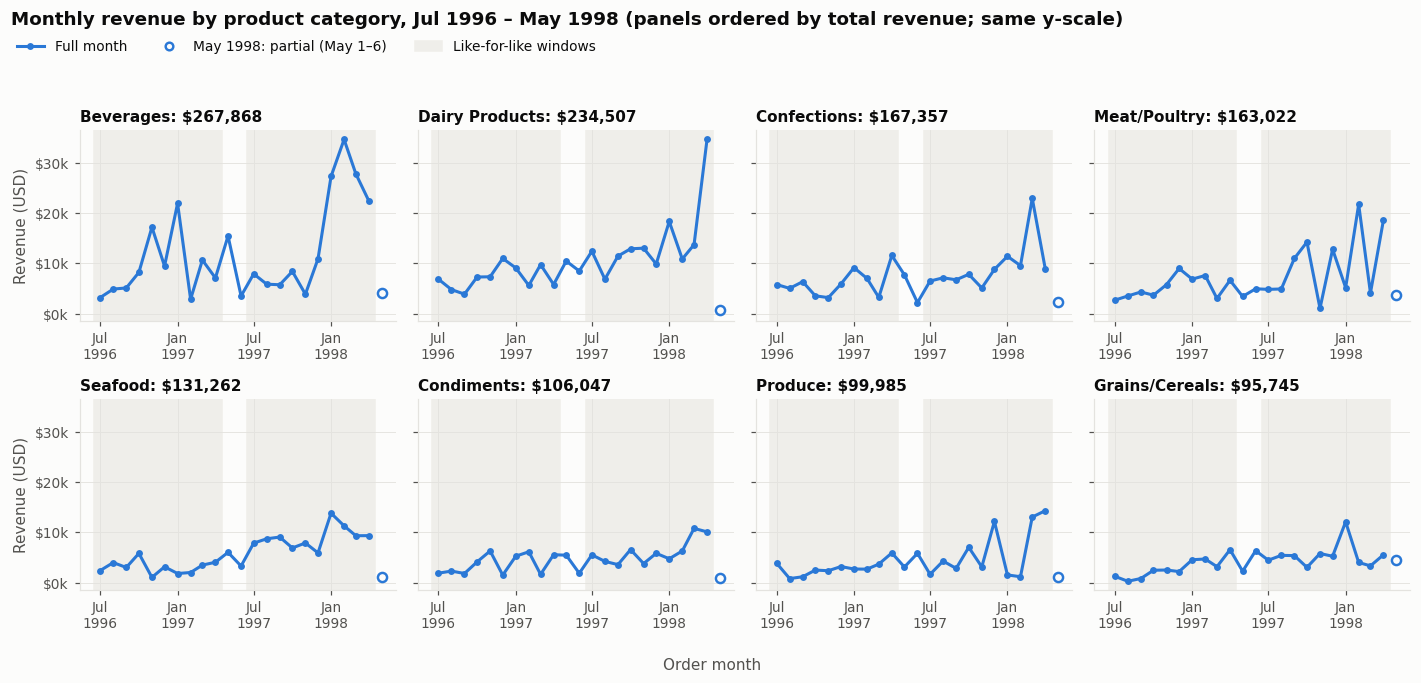


Monthly revenue (USD) by category:


CategoryName,Beverages,Dairy Products,Confections,Meat/Poultry,Seafood,Condiments,Produce,Grains/Cereals
1996-07,"3,182.50","6,838.34","5,775.15","2,661.72","2,400.32","1,878.20","3,868.80","1,256.86"
1996-08,"4,866.88","4,761.70","5,006.77","3,495.66","3,982.74","2,296.60",804.32,270.60
1996-09,"5,088.40","3,857.60","6,337.00","4,291.00","3,009.80","1,813.60","1,164.80",819.20
1996-10,"8,187.36","7,260.43","3,528.59","3,651.30","5,812.00","4,124.32","2,491.16","2,460.56"
1996-11,"17,162.06","7,309.72","3,165.38","5,757.18","1,042.90","6,290.23","2,365.88","2,506.70"
1996-12,"9,431.80","10,952.66","5,872.65","8,956.80","3,143.46","1,497.44","3,190.82","2,194.00"
1997-01,"21,904.16","9,066.40","9,128.11","6,842.85","1,811.75","5,252.07","2,704.92","4,547.80"
1997-02,"2,845.84","5,584.84","6,978.88","7,561.02","2,010.90","6,128.86","2,679.60","4,693.70"
1997-03,"10,636.88","9,728.90","3,209.93","2,998.48","3,483.50","1,645.13","3,676.80","3,167.60"
1997-04,"7,074.35","5,775.60","11,538.61","6,613.44","4,048.29","5,544.40","5,893.86","6,544.40"


In [120]:
# 5a) Revenue by product category over time: monthly, one panel per category, shared y-axis
cats = sales.groupby("CategoryName").Revenue.sum().sort_values(ascending=False).index
months = pd.period_range(FIRST_DAY.to_period("M"), LAST_MONTH, freq="M")
cat_m = (sales.pivot_table(index="Month", columns="CategoryName", values="Revenue", aggfunc="sum", fill_value=0)
         .reindex(months, fill_value=0)[cats])
mx = months.to_timestamp()
full_m = [not (LAST_MONTH_PARTIAL and m == LAST_MONTH) for m in months]

fig, axes = plt.subplots(2, 4, figsize=(13, 6.2), sharex=True, sharey=True)
for ax, cat in zip(axes.flat, cats):
    for pair in WINDOWS.values():
        for _, start, end in pair:
            ax.axvspan(pd.Timestamp(start).to_period("M").to_timestamp() - pd.Timedelta(days=15),
                       pd.Timestamp(end).to_period("M").to_timestamp() + pd.Timedelta(days=15),
                       color=WINDOW_SHADE, zorder=0)
    y = cat_m[cat]
    ax.plot(mx[full_m], y[full_m], color=BLUE, marker="o", markersize=3.5)
    if LAST_MONTH_PARTIAL:
        ax.plot(mx[-1:], y.iloc[-1:], linestyle="none", marker="o", markersize=6, markerfacecolor=SURFACE,
                markeredgecolor=BLUE, markeredgewidth=1.6)
    ax.set_title(f"{cat}: ${y.sum():,.0f}", fontsize=10)
    ax.yaxis.set_major_formatter(usd_k)
    ax.xaxis.set_major_locator(mticker.FixedLocator(
        [pd.Timestamp(d).toordinal() - pd.Timestamp("1970-01-01").toordinal() for d in
         ["1996-07-01", "1997-01-01", "1997-07-01", "1998-01-01"]]))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))
    ax.tick_params(labelbottom=True)
for ax in axes[:, 0]:
    ax.set_ylabel("Revenue (USD)")
fig.supxlabel("Order month", color=INK_2, fontsize=10)
fig.legend(handles=[Line2D([], [], color=BLUE, marker="o", markersize=3.5, label="Full month"),
                    Line2D([], [], linestyle="none", marker="o", markerfacecolor=SURFACE, markeredgecolor=BLUE,
                           markeredgewidth=1.6, label=f"{LAST_DAY:%b %Y}: partial ({LAST_DAY:%b} 1–{LAST_DAY.day})"),
                    Patch(color=WINDOW_SHADE, label="Like-for-like windows")],
           loc="upper left", ncol=3, bbox_to_anchor=(0.005, 0.955))
fig.suptitle(f"Monthly revenue by product category, {FIRST_DAY:%b %Y} – {LAST_DAY:%b %Y} "
             "(panels ordered by total revenue; same y-scale)", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.91)); plt.show()
m_index = [str(m) + (" (partial)" if LAST_MONTH_PARTIAL and m == LAST_MONTH else "") for m in months]
show_table(cat_m.set_axis(m_index), "Monthly revenue (USD) by category:")

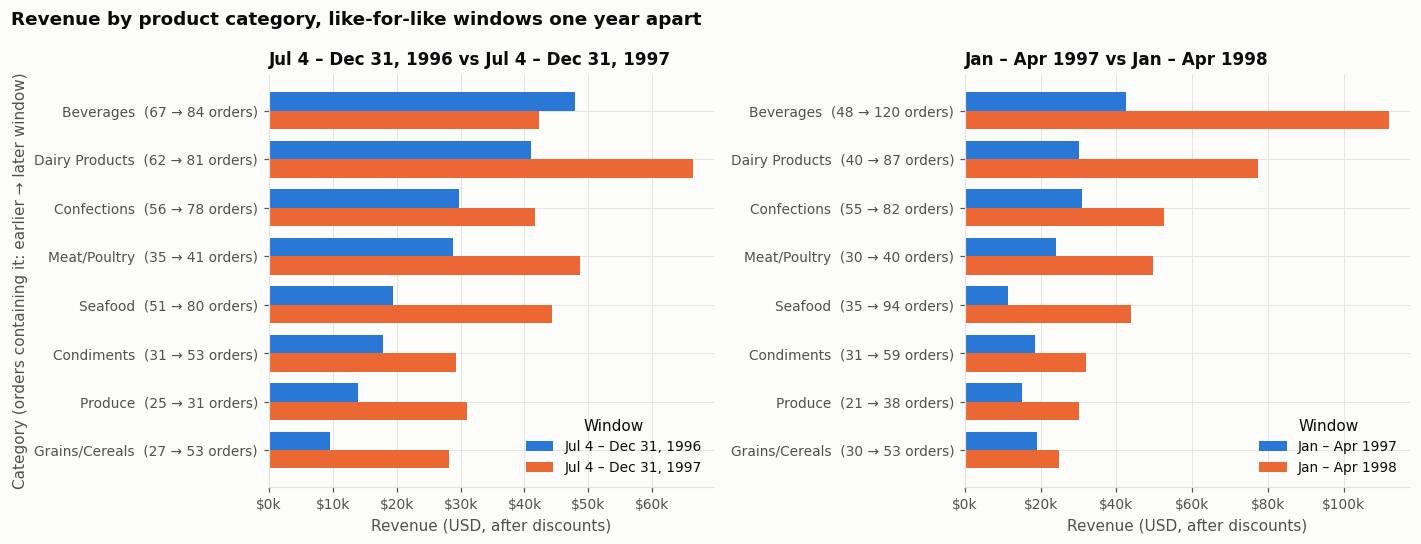


Category revenue (USD), orders and units by like-for-like window:


,window,period,CategoryName,orders,units,revenue,revenue_change_pct
0,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1996",Beverages,67,1842,"47,919.00",NaN
1,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1996",Dairy Products,62,2086,"40,980.45",NaN
2,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1996",Confections,56,1357,"29,685.55",NaN
3,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1996",Meat/Poultry,35,950,"28,813.66",NaN
4,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1996",Seafood,51,1286,"19,391.22",NaN
5,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1996",Condiments,31,962,"17,900.38",NaN
6,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1996",Produce,25,549,"13,885.78",NaN
7,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1996",Grains/Cereals,27,549,"9,507.92",NaN
8,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1997",Beverages,84,2052,"42,195.40",-11.94
9,Jul 4 – Dec 31,"Jul 4 – Dec 31, 1997",Dairy Products,81,2237,"66,340.52",61.88


In [121]:
# 5b) Like-for-like by category: both comparison windows
rows = []
for name, pair in WINDOWS.items():
    for label, start, end in pair:
        w = in_window(sales, start, end)
        g = w.groupby("CategoryName").agg(orders=("OrderID", "nunique"), units=("Quantity", "sum"),
                                          revenue=("Revenue", "sum")).reindex(cats, fill_value=0)
        rows.append(g.assign(window=name, period=label).reset_index())
cat_w = pd.concat(rows, ignore_index=True)
cat_w["revenue_change_pct"] = cat_w.groupby(["window", "CategoryName"]).revenue.pct_change() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))   # not sharey: each panel has its own order-count labels
for ax, (name, g) in zip(axes, cat_w.groupby("window", sort=False)):
    (ea, la) = WINDOWS[name]
    e, l = g[g.period == ea[0]].set_index("CategoryName"), g[g.period == la[0]].set_index("CategoryName")
    yy = range(len(cats)); h = 0.38
    ax.barh([i - h / 2 for i in yy], e.revenue[cats], height=h, color=BLUE, label=ea[0])
    ax.barh([i + h / 2 for i in yy], l.revenue[cats], height=h, color=ORANGE, label=la[0])
    ax.set_yticks(list(yy))
    ax.set_yticklabels([f"{c}  ({e.orders[c]} → {l.orders[c]} orders)" for c in cats])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(usd_k)
    ax.set_xlabel("Revenue (USD, after discounts)")
    ax.set_title(f"{ea[0]} vs {la[0]}", fontsize=11)
    ax.legend(loc="lower right", title="Window")
axes[0].set_ylabel("Category (orders containing it: earlier → later window)")
fig.suptitle("Revenue by product category, like-for-like windows one year apart",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()
show_table(cat_w[["window", "period", "CategoryName", "orders", "units", "revenue", "revenue_change_pct"]],
           "Category revenue (USD), orders and units by like-for-like window:")